# Premier League match-outcome prediction

**Prototype:** 2026/27 Matchweek 8 · **data cutoff:** 19 October 2026 · **forecast frozen before the round**

## Project context

The goal is to estimate three pre-kickoff probabilities for each match:

- **H (0):** home win
- **D (1):** draw
- **A (2):** away win

The notebook compares the three requested model families—**multinomial logistic regression, random forest, and XGBoost**—then saves every fitted pipeline and an inference-ready champion bundle. It predicts the nine Saturday/Sunday fixtures still in the weekend scope and retains Friday's opener separately as a clearly labelled frozen backcast.

This is a classification and probability-estimation problem, not an exact-score model. The output should be read as uncertainty-aware forecasts, not betting advice.

## Success criteria

1. No same-match or future information enters a predictor.
2. All preprocessing is fitted inside chronological training windows.
3. Model selection uses expanding-season validation; 2026/27 remains an untouched final test.
4. Primary metric: **multiclass log loss** (lower is better). Secondary metrics: macro-F1, balanced accuracy, accuracy, draw recall, and multiclass Brier score.
5. Forecast probabilities sum to one and saved artifacts reproduce the in-memory probabilities exactly.

> **Timing note (24 October 2026):** Matchweek 8 runs 23–25 October. Ipswich Town v Nottingham Forest was scheduled for Friday, so that fixture is now earlier in the round. It remains in the table as a frozen pre-round prediction; no Matchweek 8 result is used anywhere in training.


## End-to-end workflow

```text
Problem framing
      ↓
Data contract, quality checks, and dataset understanding
      ↓
Descriptive EDA (including target drift and home advantage)
      ↓
Leakage audit
      ↓
Strictly historical team form + Elo + calendar features
      ↓
Expanding-season model selection
      ↓
Untouched 2026/27 evaluation and interpretation
      ↓
Refit on all completed matches through 19 Oct 2026
      ↓
Frozen Matchweek 8 features and three-model forecasts
      ↓
Persist pipelines, state, metadata, metrics, and predictions
```

The key design principle is **information availability at kickoff**. Final scores, half-time scores, shots, corners, fouls, and cards are legitimate historical signals only after they have been shifted into summaries of earlier matches. They are never used from the match being predicted.


## Assumptions and scope

- The supplied CSV is treated as the authoritative modeling dataset, but it contains no source/provenance field. Structural checks cannot prove that every historical score is official.
- The CSV contains completed matches only. The Matchweek 8 fixture table is supplied separately from the official Premier League schedule.
- Team names are normalized to the CSV convention (for example, `Man City` and `Nott'm Forest`).
- Referee is omitted: it can be known pre-match, but a portable forecasting input should not depend on appointments always being present.
- Injuries, expected lineups, transfers, betting odds, and advanced event data are out of scope for this first notebook prototype.
- Coventry and Hull have only seven league matches in this dataset. History-count features expose that cold-start risk to the models.


In [1]:
# Reproducible setup and centralized configuration
from __future__ import annotations

import copy
import hashlib
import json
import math
import platform
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_recall_fscore_support,
    recall_score,
)
from sklearn.calibration import calibration_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from xgboost import XGBClassifier
# Import the local feature-builder module from a checkout of this project.
import sys
for _location in (Path.cwd() / "src", Path.cwd().parent / "src"):
    if _location.is_dir() and str(_location) not in sys.path:
        sys.path.insert(0, str(_location))
from epl_feature_builder import FrozenEPLFeatureBuilder, __version__ as FEATURE_BUILDER_VERSION

SEED = 42
ROLLING_WINDOW = 5
LONG_WINDOW = 10
TEST_SEASON = "2026/27"
TARGET_ORDER = [0, 1, 2]
TARGET_LABELS = {0: "Home win", 1: "Draw", 2: "Away win"}
TARGET_SHORT = {0: "H", 1: "D", 2: "A"}
FIXTURE_SOURCE = "https://www.premierleague.com/en/matches/results/2026-27"
LAST_INCLUDED_KICKOFF_UK = pd.Timestamp("2026-10-19 20:00")
DATA_CUTOFF = "Through matches completed on 19 Oct 2026 (latest included kickoff: 20:00 UK local)"

np.random.seed(SEED)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")

candidate_data_paths = [
    Path.cwd() / "data" / "EPL_data.csv",
    Path.cwd().parent / "data" / "EPL_data.csv",
]
DATA_PATH = next((path for path in candidate_data_paths if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "EPL_data.csv was not found. Run from the notebook directory or project root."
    )

NOTEBOOK_ROOT = DATA_PATH.parent.parent
ARTIFACT_DIR = NOTEBOOK_ROOT / "artifacts"
FIGURE_DIR = ARTIFACT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

PACKAGE_VERSIONS = {
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit_learn": sklearn.__version__,
    "xgboost": xgboost.__version__,
    "matplotlib": plt.matplotlib.__version__,
    "seaborn": sns.__version__,
    "joblib": joblib.__version__,
    "feature_builder": FEATURE_BUILDER_VERSION,
}

print(f"Data: {DATA_PATH.resolve()}")
print(f"Artifacts: {ARTIFACT_DIR.resolve()}")
print(PACKAGE_VERSIONS)


Data: C:\Users\obinn\Documents\New project 3\output\jupyter-notebook\data\EPL_data.csv
Artifacts: C:\Users\obinn\Documents\New project 3\output\jupyter-notebook\artifacts
{'python': '3.13.5', 'pandas': '2.2.3', 'numpy': '2.1.3', 'scikit_learn': '1.6.1', 'xgboost': '3.1.0', 'matplotlib': '3.10.0', 'seaborn': '0.13.2', 'joblib': '1.4.2', 'feature_builder': '0.1.0'}


## 1. Load the data and enforce the data contract

**Unit of observation:** one completed Premier League match.

The result is represented twice in the raw file: `FTR` uses H/D/A and `MatchResult` uses 0/1/2. We verify their agreement and model `MatchResult`. All quality checks fail loudly so that a changed data extract does not silently flow through the notebook.


In [2]:
raw = pd.read_csv(DATA_PATH)
raw["MatchDateTime"] = pd.to_datetime(
    raw["Date"].astype(str) + " " + raw["Time"].astype(str), errors="raise"
)
raw = raw.sort_values(["MatchDateTime", "HomeTeam", "AwayTeam"]).reset_index(drop=True)

# Fail rather than silently train on a refreshed file containing Matchweek 8 or later results.
if raw["MatchDateTime"].max() != LAST_INCLUDED_KICKOFF_UK:
    raise ValueError(
        f"Frozen forecast expects latest kickoff {LAST_INCLUDED_KICKOFF_UK}; "
        f"dataset ends at {raw['MatchDateTime'].max()}. Review the cutoff before rerunning."
    )

required_columns = {
    "Div", "Date", "Time", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR",
    "HTHG", "HTAG", "HTR", "Referee", "HS", "AS", "HST", "AST", "HF", "AF",
    "HC", "AC", "HY", "AY", "HR", "AR", "MatchResult", "Season",
}
missing_columns = required_columns.difference(raw.columns)
assert not missing_columns, f"Missing columns: {sorted(missing_columns)}"
assert raw["MatchDateTime"].is_monotonic_increasing
assert raw.isna().sum().sum() == 0
assert raw.duplicated().sum() == 0
assert not raw.duplicated(["Season", "HomeTeam", "AwayTeam"]).any()
assert (raw["HomeTeam"] != raw["AwayTeam"]).all()
assert (raw["HST"] <= raw["HS"]).all() and (raw["AST"] <= raw["AS"]).all()
assert (raw["HTHG"] <= raw["FTHG"]).all() and (raw["HTAG"] <= raw["FTAG"]).all()

expected_ftr = np.select(
    [raw["FTHG"] > raw["FTAG"], raw["FTHG"] == raw["FTAG"]], ["H", "D"], default="A"
)
expected_numeric = pd.Series(expected_ftr).map({"H": 0, "D": 1, "A": 2}).to_numpy()
assert np.array_equal(expected_ftr, raw["FTR"].to_numpy())
assert np.array_equal(expected_numeric, raw["MatchResult"].to_numpy())

season_order = raw["Season"].drop_duplicates().tolist()
audit = pd.DataFrame(
    {
        "Check": [
            "Rows", "Columns", "Date range", "Seasons", "Unique clubs",
            "Missing cells", "Exact duplicate rows", "Duplicate season fixtures",
        ],
        "Result": [
            f"{len(raw):,}",
            f"{raw.shape[1] - 1:,} raw + parsed timestamp",
            f"{raw['MatchDateTime'].min():%d %b %Y} → {raw['MatchDateTime'].max():%d %b %Y}",
            ", ".join(season_order),
            raw[["HomeTeam", "AwayTeam"]].stack().nunique(),
            int(raw.isna().sum().sum()),
            int(raw.duplicated().sum()),
            int(raw.duplicated(["Season", "HomeTeam", "AwayTeam"]).sum()),
        ],
    }
)
display(audit)
display(raw.head(3))


,Check,Result
0,Rows,"1,590"
1,Columns,26 raw + parsed timestamp
2,Date range,05 Aug 2022 → 19 Oct 2026
3,Seasons,"2022/23, 2023/24, 2024/25, 2025/26, 2026/27"
4,Unique clubs,27
5,Missing cells,0
6,Exact duplicate rows,0
7,Duplicate season fixtures,0


,Div,Date,Time,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,Referee,HS,AS,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR,MatchResult,Season,MatchDateTime
0,E0,2022-08-05,20:00,Crystal Palace,Arsenal,0,2,A,0,1,A,A Taylor,10,10,2,2,16,11,3,5,1,2,0,0,2,2022/23,2022-08-05 20:00:00
1,E0,2022-08-06,12:30,Fulham,Liverpool,2,2,D,1,0,H,A Madley,9,11,3,4,7,9,4,4,2,0,0,0,1,2022/23,2022-08-06 12:30:00
2,E0,2022-08-06,15:00,Bournemouth,Aston Villa,2,0,H,1,0,H,P Bankes,7,15,3,2,18,16,5,5,3,3,0,0,0,2022/23,2022-08-06 15:00:00


### Data dictionary

| Group | Columns | Meaning | Modeling treatment |
|---|---|---|---|
| Fixture identity | `Date`, `Time`, `HomeTeam`, `AwayTeam`, `Season` | Known before kickoff | Calendar, rest, identity, and split fields |
| Result | `FTHG`, `FTAG`, `FTR`, `MatchResult` | Full-time score/outcome | Target or historical lag only |
| Half-time | `HTHG`, `HTAG`, `HTR` | State after kickoff | Historical lag only |
| Match performance | `HS/AS`, `HST/AST`, `HC/AC` | Shots, shots on target, corners | Historical lag only |
| Discipline | `HF/AF`, `HY/AY`, `HR/AR` | Fouls and cards | Historical lag only |
| Administration | `Div`, `Referee` | Competition/referee | `Div` is constant; referee omitted |

The raw file is unusually clean: there are no missing cells or duplicates, and the encoded outcomes agree with the final scores. That makes the **temporal leakage problem**, not missing-data repair, the central data-engineering challenge.


## 2. Exploratory data analysis

EDA below is descriptive. Some plots use same-match statistics to understand the dataset; their presence in EDA does **not** make those columns valid pre-match predictors.


,Season,Matches,Teams,Start,End,Complete_380
0,2022/23,380,20,2022-08-05 20:00:00,2023-05-28 16:30:00,True
1,2023/24,380,20,2023-08-11 20:00:00,2024-05-19 16:00:00,True
2,2024/25,380,20,2024-08-16 20:00:00,2025-05-25 16:00:00,True
3,2025/26,380,20,2025-08-15 20:00:00,2026-05-24 16:00:00,True
4,2026/27,70,20,2026-08-21 20:00:00,2026-10-19 20:00:00,False


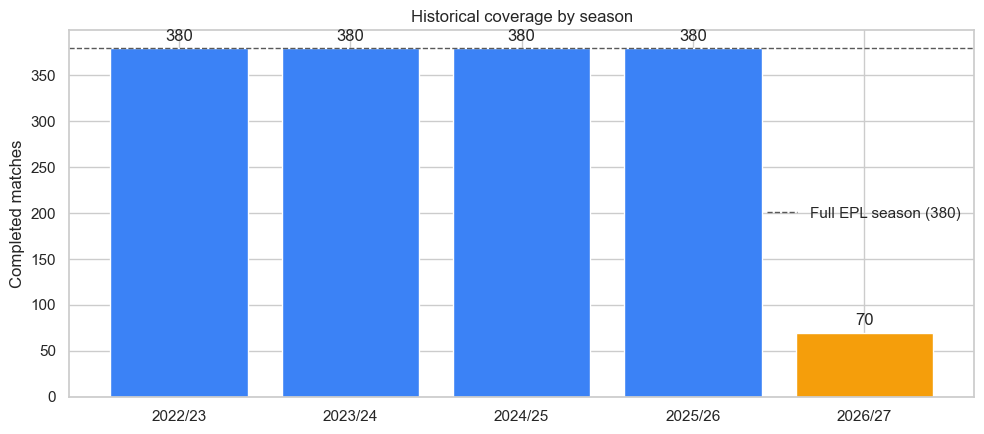

Interpretation: 4 seasons are complete (380 matches each). The current 2026/27 sample has 70 matches—exactly seven per team—so it is a deliberately small, recent holdout rather than another full season.


In [3]:
season_summary = (
    raw.groupby("Season", sort=False)
    .agg(
        Matches=("MatchResult", "size"),
        Teams=("HomeTeam", "nunique"),
        Start=("MatchDateTime", "min"),
        End=("MatchDateTime", "max"),
    )
    .reset_index()
)
season_summary["Complete_380"] = season_summary["Matches"].eq(380)
display(season_summary)

fig, ax = plt.subplots(figsize=(10, 4.5))
colors = ["#3b82f6" if value == 380 else "#f59e0b" for value in season_summary["Matches"]]
bars = ax.bar(season_summary["Season"], season_summary["Matches"], color=colors)
ax.axhline(380, color="0.35", linestyle="--", linewidth=1, label="Full EPL season (380)")
ax.bar_label(bars, padding=3)
ax.set(title="Historical coverage by season", ylabel="Completed matches", xlabel="")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "01_season_coverage.png", dpi=160, bbox_inches="tight")
plt.show()

complete_count = int(season_summary["Complete_380"].sum())
current_matches = int(season_summary.iloc[-1]["Matches"])
print(
    f"Interpretation: {complete_count} seasons are complete (380 matches each). "
    f"The current 2026/27 sample has {current_matches} matches—exactly seven per team—"
    "so it is a deliberately small, recent holdout rather than another full season."
)


FTR,Home %,Draw %,Away %
Season,,,
2022/23,48.400,22.900,28.700
2023/24,46.100,21.600,32.400
2024/25,40.800,24.500,34.700
2025/26,42.600,27.400,30.000
2026/27,40.000,28.600,31.400


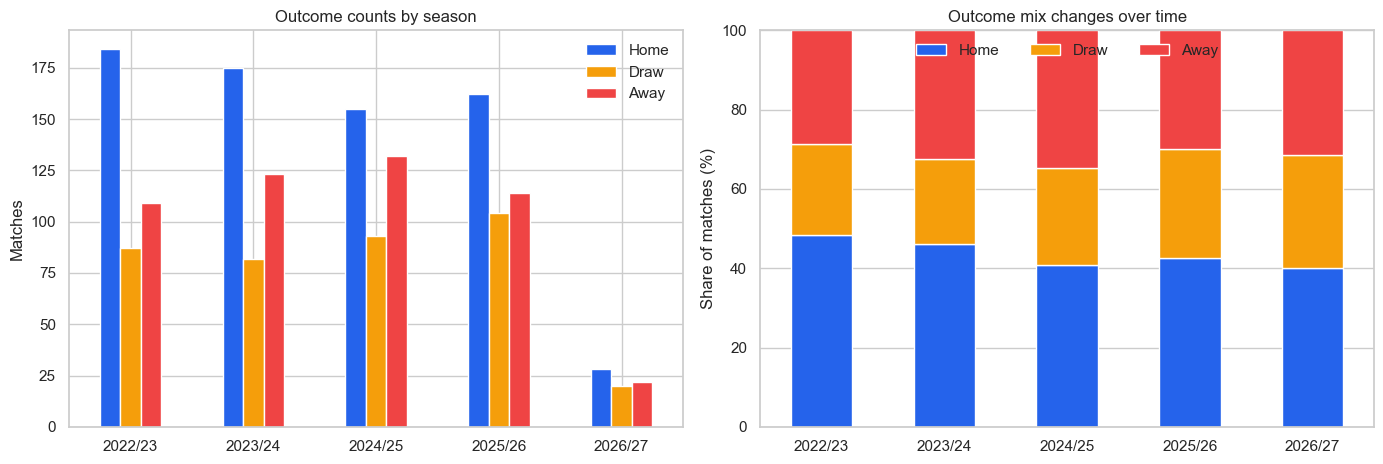

Interpretation: home wins are the largest class at 44.3%, followed by away wins (31.4%) and draws (24.3%). The home-win rate spans 8.4% across seasons, which is evidence of temporal drift and a reason to avoid random splits.


In [4]:
outcome_counts = (
    raw.groupby(["Season", "FTR"], sort=False).size().unstack(fill_value=0)
    .reindex(index=season_order, columns=["H", "D", "A"])
)
outcome_rates = outcome_counts.div(outcome_counts.sum(axis=1), axis=0)
display((outcome_rates * 100).round(1).rename(columns={"H": "Home %", "D": "Draw %", "A": "Away %"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
outcome_counts.rename(columns={"H": "Home", "D": "Draw", "A": "Away"}).plot(
    kind="bar", ax=axes[0], color=["#2563eb", "#f59e0b", "#ef4444"]
)
axes[0].set(title="Outcome counts by season", xlabel="", ylabel="Matches")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(frameon=False)

(outcome_rates * 100).rename(columns={"H": "Home", "D": "Draw", "A": "Away"}).plot(
    kind="bar", stacked=True, ax=axes[1], color=["#2563eb", "#f59e0b", "#ef4444"]
)
axes[1].set(title="Outcome mix changes over time", xlabel="", ylabel="Share of matches (%)", ylim=(0, 100))
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(frameon=False, ncol=3, loc="upper center")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "02_outcome_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

overall_rates = raw["FTR"].value_counts(normalize=True).reindex(["H", "D", "A"])
home_range = outcome_rates["H"].max() - outcome_rates["H"].min()
print(
    "Interpretation: home wins are the largest class at "
    f"{overall_rates['H']:.1%}, followed by away wins ({overall_rates['A']:.1%}) "
    f"and draws ({overall_rates['D']:.1%}). The home-win rate spans {home_range:.1%} "
    "across seasons, which is evidence of temporal drift and a reason to avoid random splits."
)


Venue,Away,Home
Metric,,
Corners,4.662,5.608
Goals,1.333,1.618
Shots,11.756,14.253
Shots on target,4.110,4.913
Yellow cards,2.104,1.790


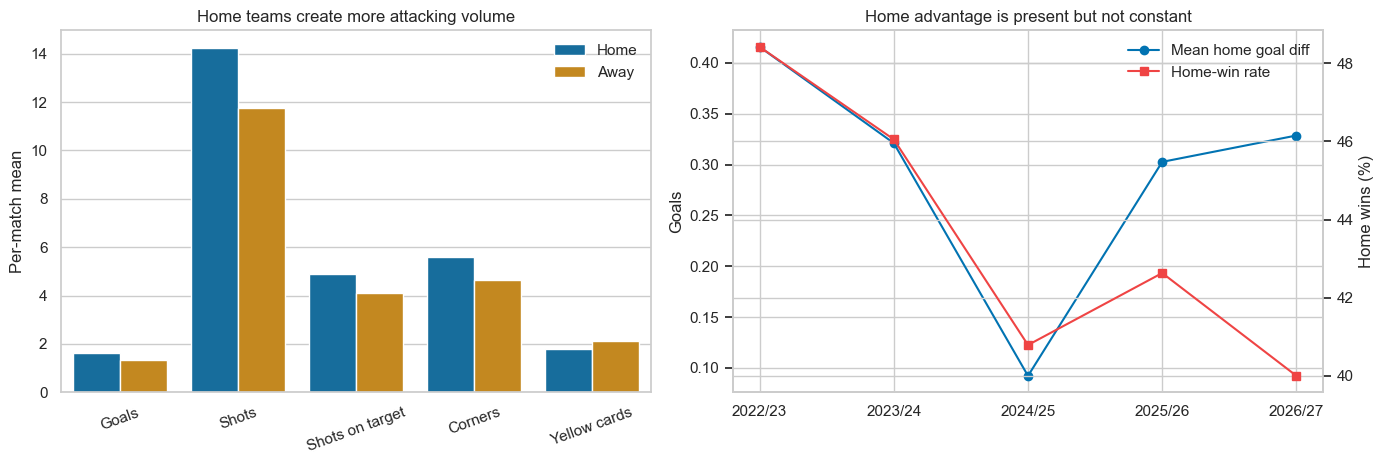

Interpretation: home teams score 0.285 more goals per match on average and also lead in shots, shots on target, and corners. Home advantage should therefore be learned explicitly, while the season plot warns us not to treat it as a fixed probability.


In [5]:
metric_pairs = {
    "Goals": ("FTHG", "FTAG"),
    "Shots": ("HS", "AS"),
    "Shots on target": ("HST", "AST"),
    "Corners": ("HC", "AC"),
    "Yellow cards": ("HY", "AY"),
}
mean_rows = []
for label, (home_col, away_col) in metric_pairs.items():
    mean_rows.extend(
        [
            {"Metric": label, "Venue": "Home", "Mean": raw[home_col].mean()},
            {"Metric": label, "Venue": "Away", "Mean": raw[away_col].mean()},
        ]
    )
venue_means = pd.DataFrame(mean_rows)
display(venue_means.pivot(index="Metric", columns="Venue", values="Mean").round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.barplot(data=venue_means, x="Metric", y="Mean", hue="Venue", ax=axes[0])
axes[0].set(title="Home teams create more attacking volume", xlabel="", ylabel="Per-match mean")
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend(frameon=False)

season_home = (
    raw.assign(GoalDiff=raw["FTHG"] - raw["FTAG"], HomeWin=(raw["FTR"] == "H").astype(int))
    .groupby("Season", sort=False)
    .agg(MeanGoalDiff=("GoalDiff", "mean"), HomeWinRate=("HomeWin", "mean"))
    .reset_index()
)
axes[1].plot(season_home["Season"], season_home["MeanGoalDiff"], marker="o", label="Mean home goal diff")
ax2 = axes[1].twinx()
ax2.plot(
    season_home["Season"], season_home["HomeWinRate"] * 100,
    marker="s", color="#ef4444", label="Home-win rate"
)
axes[1].set(title="Home advantage is present but not constant", xlabel="", ylabel="Goals")
ax2.set(ylabel="Home wins (%)")
axes[1].tick_params(axis="x", rotation=0)
lines1, labels1 = axes[1].get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
axes[1].legend(lines1 + lines2, labels1 + labels2, frameon=False, loc="best")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "03_home_advantage.png", dpi=160, bbox_inches="tight")
plt.show()

home_goal_edge = raw["FTHG"].mean() - raw["FTAG"].mean()
print(
    f"Interpretation: home teams score {home_goal_edge:.3f} more goals per match on average and "
    "also lead in shots, shots on target, and corners. Home advantage should therefore be learned "
    "explicitly, while the season plot warns us not to treat it as a fixed probability."
)


,Position,GP,Points,GF,GA,GD,PPG
Team,,,,,,,
Man City,1,7,21,19,7,12,3.000
Arsenal,2,7,18,11,5,6,2.571
Brighton,3,7,16,23,5,18,2.286
Chelsea,4,7,13,17,13,4,1.857
Liverpool,5,7,12,9,8,1,1.714
Brentford,6,7,10,13,8,5,1.429
Leeds,7,7,10,9,6,3,1.429
Everton,8,7,10,8,7,1,1.429
Hull,9,7,9,8,7,1,1.286


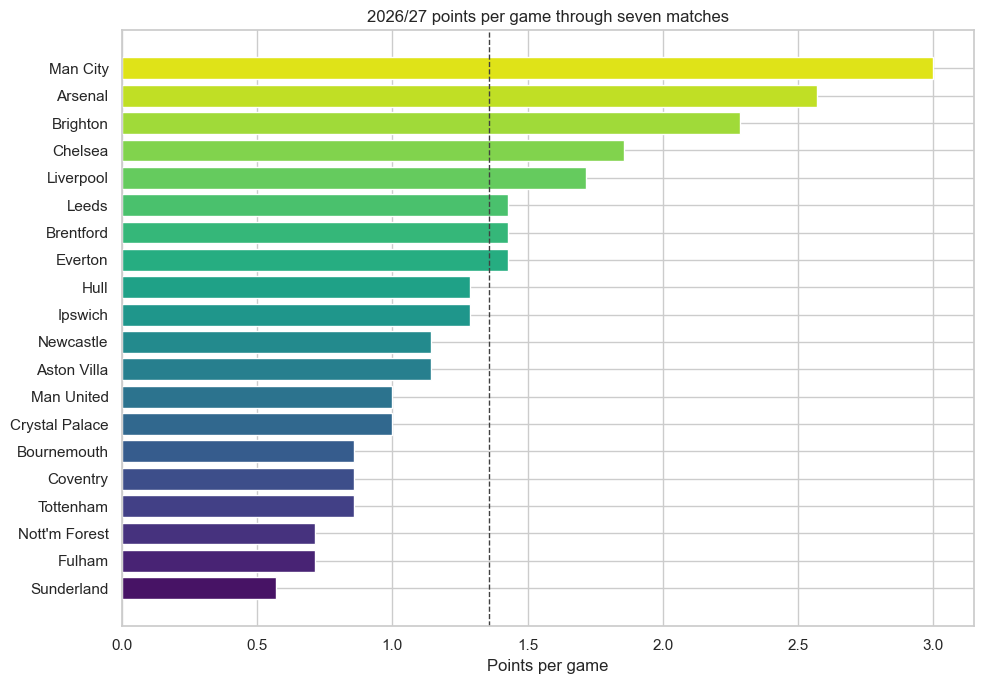

Interpretation: every team has only seven observations in the current-season table. It is useful context, but early standings are noisy; the feature builder therefore combines recent form, longer history, regressed Elo, and explicit history counts.


In [6]:
# Current-season table: descriptive context for the forecast cutoff
current = raw.loc[raw["Season"].eq(TEST_SEASON)].copy()
home_rows = current[["HomeTeam", "FTHG", "FTAG", "FTR"]].rename(
    columns={"HomeTeam": "Team", "FTHG": "GF", "FTAG": "GA"}
)
home_rows["Points"] = home_rows["FTR"].map({"H": 3, "D": 1, "A": 0})
away_rows = current[["AwayTeam", "FTAG", "FTHG", "FTR"]].rename(
    columns={"AwayTeam": "Team", "FTAG": "GF", "FTHG": "GA"}
)
away_rows["Points"] = away_rows["FTR"].map({"A": 3, "D": 1, "H": 0})
team_long = pd.concat([home_rows, away_rows], ignore_index=True)
current_table = (
    team_long.groupby("Team")
    .agg(GP=("Team", "size"), Points=("Points", "sum"), GF=("GF", "sum"), GA=("GA", "sum"))
    .assign(GD=lambda frame: frame["GF"] - frame["GA"], PPG=lambda frame: frame["Points"] / frame["GP"])
    .sort_values(["Points", "GD", "GF"], ascending=False)
)
current_table.insert(0, "Position", range(1, len(current_table) + 1))
display(current_table)

plot_table = current_table.sort_values("PPG")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(plot_table.index, plot_table["PPG"], color=sns.color_palette("viridis", len(plot_table)))
ax.axvline(team_long["Points"].mean(), color="0.25", linestyle="--", linewidth=1)
ax.set(title="2026/27 points per game through seven matches", xlabel="Points per game", ylabel="")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "04_current_table_ppg.png", dpi=160, bbox_inches="tight")
plt.show()
print(
    "Interpretation: every team has only seven observations in the current-season table. "
    "It is useful context, but early standings are noisy; the feature builder therefore combines "
    "recent form, longer history, regressed Elo, and explicit history counts."
)


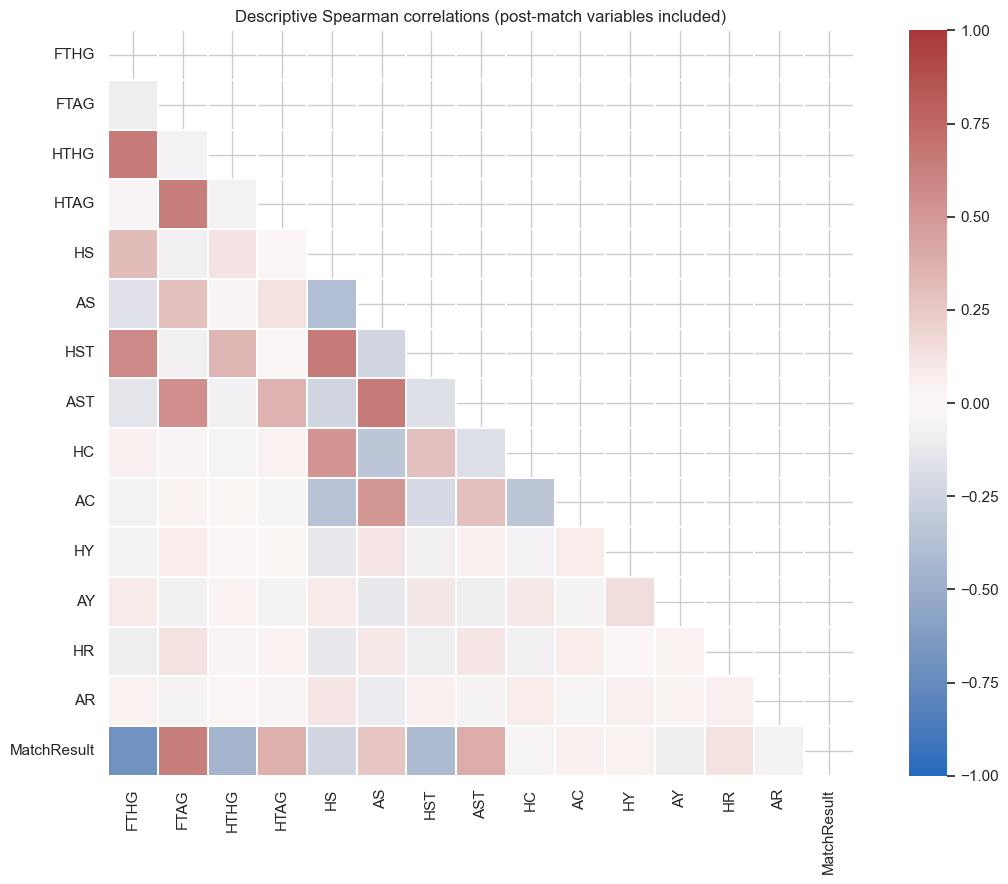

Interpretation: goals, shots on target, and the result are related—as football logic suggests. That relationship is descriptive, not predictive at kickoff. Feeding these same-match values to a model would reveal the answer and produce misleadingly high evaluation scores.


In [7]:
descriptive_columns = [
    "FTHG", "FTAG", "HTHG", "HTAG", "HS", "AS", "HST", "AST",
    "HC", "AC", "HY", "AY", "HR", "AR", "MatchResult",
]
descriptive_corr = raw[descriptive_columns].corr(method="spearman")
mask = np.triu(np.ones_like(descriptive_corr, dtype=bool))
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(
    descriptive_corr, mask=mask, cmap="vlag", center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.3, ax=ax
)
ax.set_title("Descriptive Spearman correlations (post-match variables included)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "05_descriptive_correlation.png", dpi=160, bbox_inches="tight")
plt.show()
print(
    "Interpretation: goals, shots on target, and the result are related—as football logic suggests. "
    "That relationship is descriptive, not predictive at kickoff. Feeding these same-match values "
    "to a model would reveal the answer and produce misleadingly high evaluation scores."
)


## 3. Leakage audit and feature policy

### Never used directly as predictors

- Direct target/redundancy: `MatchResult`, `FTR`
- Final and half-time scores: `FTHG`, `FTAG`, `HTHG`, `HTAG`, `HTR`
- Full-match events: shots, shots on target, fouls, corners, yellow cards, red cards
- `Div` (constant) and `Referee` (omitted for a stable forecast contract)

### Allowed after strict historical shifting

Earlier matches contribute rolling points, goals, shot differentials, shots-on-target differentials, corner differentials, discipline, wins, draws, clean sheets, venue form, season-to-date form, rest, and Elo.

The feature builder snapshots every fixture at a kickoff timestamp **before** updating state with any result at that timestamp. This removes dependence on CSV row order for simultaneous kickoffs.


## 4. Strictly pre-match feature engineering

For each team, the state contains:

- last-5 and last-10 overall form;
- last-5 form at the relevant venue;
- season-to-date averages;
- pre-match Elo (regressed 25% toward 1500 at a new season);
- prior-match counts and days since the previous match.

Home and away snapshots are retained separately and converted into difference features. Missing early-history values are intentionally left as `NaN`; each model pipeline learns training-only median imputations and missingness indicators.


In [8]:
POST_MATCH_COLUMNS = {
    "FTHG", "FTAG", "FTR", "HTHG", "HTAG", "HTR", "HS", "AS", "HST", "AST",
    "HF", "AF", "HC", "AC", "HY", "AY", "HR", "AR", "MatchResult",
}
FORM_METRICS = [
    "points", "goals_for", "goals_against", "goal_diff", "shot_diff", "sot_diff",
    "corner_diff", "discipline", "win", "draw", "clean_sheet",
]
LONG_METRICS = ["points", "goals_for", "goals_against", "goal_diff"]
VENUE_METRICS = ["points", "goal_diff", "win"]
SEASON_METRICS = ["points", "goals_for", "goals_against", "goal_diff", "shot_diff", "sot_diff"]


def fresh_state() -> dict:
    return {
        "history": {},
        "venue_history": {},
        "season_stats": {},
        "last_played": {},
        "elo": {},
        "current_season": None,
    }


def prepare_season(state: dict, season: str) -> None:
    if state["current_season"] == season:
        return
    if state["current_season"] is not None:
        state["elo"] = {
            team: 1500.0 + 0.75 * (rating - 1500.0)
            for team, rating in state["elo"].items()
        }
    state["current_season"] = season


def mean_or_nan(records: list[dict], key: str) -> float:
    return float(np.mean([record[key] for record in records])) if records else np.nan


def team_snapshot(team: str, venue: str, timestamp: pd.Timestamp, season: str, state: dict) -> dict:
    history = state["history"].get(team, [])
    recent5 = history[-ROLLING_WINDOW:]
    recent10 = history[-LONG_WINDOW:]
    venue_history = state["venue_history"].get((team, venue), [])[-ROLLING_WINDOW:]
    season_key = (season, team)
    season_stats = state["season_stats"].get(season_key, {"matches": 0})
    season_matches = int(season_stats.get("matches", 0))

    previous_date = state["last_played"].get(team)
    rest_days = np.nan if previous_date is None else float(
        (timestamp.normalize() - previous_date.normalize()).days
    )
    if not np.isnan(rest_days):
        rest_days = float(np.clip(rest_days, 2, 30))

    snapshot = {
        "elo": float(state["elo"].get(team, 1500.0)),
        "history_matches": float(len(history)),
        "season_matches": float(season_matches),
        "rest_days": rest_days,
        "cold_start": float(len(history) < ROLLING_WINDOW),
    }
    for metric in FORM_METRICS:
        snapshot[f"form5_{metric}"] = mean_or_nan(recent5, metric)
    for metric in LONG_METRICS:
        snapshot[f"form10_{metric}"] = mean_or_nan(recent10, metric)
    for metric in VENUE_METRICS:
        snapshot[f"venue5_{metric}"] = mean_or_nan(venue_history, metric)
    for metric in SEASON_METRICS:
        total = float(season_stats.get(metric, 0.0))
        snapshot[f"season_{metric}"] = total / season_matches if season_matches else np.nan
    return snapshot


def fixture_snapshot(row: pd.Series, state: dict) -> dict:
    timestamp = pd.Timestamp(row["MatchDateTime"])
    home = team_snapshot(row["HomeTeam"], "H", timestamp, row["Season"], state)
    away = team_snapshot(row["AwayTeam"], "A", timestamp, row["Season"], state)
    feature_row = {
        "HomeTeam": row["HomeTeam"],
        "AwayTeam": row["AwayTeam"],
        "kickoff_hour": timestamp.hour + timestamp.minute / 60.0,
        "day_of_week": float(timestamp.dayofweek),
        "month": float(timestamp.month),
        "is_weekend": float(timestamp.dayofweek >= 5),
    }
    for key in home:
        feature_row[f"home_{key}"] = home[key]
        feature_row[f"away_{key}"] = away[key]
        feature_row[f"diff_{key}"] = home[key] - away[key]
    return feature_row


def team_match_record(row: pd.Series, home_side: bool) -> dict:
    if home_side:
        goals_for, goals_against = row["FTHG"], row["FTAG"]
        shots_for, shots_against = row["HS"], row["AS"]
        sot_for, sot_against = row["HST"], row["AST"]
        corners_for, corners_against = row["HC"], row["AC"]
        yellow, red = row["HY"], row["HR"]
    else:
        goals_for, goals_against = row["FTAG"], row["FTHG"]
        shots_for, shots_against = row["AS"], row["HS"]
        sot_for, sot_against = row["AST"], row["HST"]
        corners_for, corners_against = row["AC"], row["HC"]
        yellow, red = row["AY"], row["AR"]

    points = 3 if goals_for > goals_against else (1 if goals_for == goals_against else 0)
    return {
        "points": float(points),
        "goals_for": float(goals_for),
        "goals_against": float(goals_against),
        "goal_diff": float(goals_for - goals_against),
        "shot_diff": float(shots_for - shots_against),
        "sot_diff": float(sot_for - sot_against),
        "corner_diff": float(corners_for - corners_against),
        "discipline": float(yellow + 3 * red),
        "win": float(goals_for > goals_against),
        "draw": float(goals_for == goals_against),
        "clean_sheet": float(goals_against == 0),
    }


def update_team_state(team: str, venue: str, season: str, timestamp: pd.Timestamp, record: dict, state: dict) -> None:
    state["history"].setdefault(team, []).append(record)
    state["venue_history"].setdefault((team, venue), []).append(record)
    season_key = (season, team)
    accumulator = state["season_stats"].setdefault(
        season_key, {"matches": 0, **{metric: 0.0 for metric in SEASON_METRICS}}
    )
    accumulator["matches"] += 1
    for metric in SEASON_METRICS:
        accumulator[metric] += record[metric]
    state["last_played"][team] = timestamp


def update_after_match(row: pd.Series, state: dict) -> None:
    timestamp = pd.Timestamp(row["MatchDateTime"])
    home_team, away_team = row["HomeTeam"], row["AwayTeam"]
    home_record = team_match_record(row, home_side=True)
    away_record = team_match_record(row, home_side=False)
    update_team_state(home_team, "H", row["Season"], timestamp, home_record, state)
    update_team_state(away_team, "A", row["Season"], timestamp, away_record, state)

    home_rating = float(state["elo"].get(home_team, 1500.0))
    away_rating = float(state["elo"].get(away_team, 1500.0))
    expected_home = 1.0 / (1.0 + 10.0 ** (-(home_rating + 65.0 - away_rating) / 400.0))
    actual_home = 1.0 if row["MatchResult"] == 0 else (0.5 if row["MatchResult"] == 1 else 0.0)
    adjustment = 20.0 * (actual_home - expected_home)
    state["elo"][home_team] = home_rating + adjustment
    state["elo"][away_team] = away_rating - adjustment


def assert_no_team_repeats_at_kickoff(batch: pd.DataFrame) -> None:
    teams = pd.concat([batch["HomeTeam"], batch["AwayTeam"]], ignore_index=True)
    assert not teams.duplicated().any(), "A team appears twice at the same kickoff timestamp."


def build_historical_features(matches: pd.DataFrame) -> tuple[pd.DataFrame, np.ndarray, pd.DataFrame, dict]:
    work = matches.sort_values(["MatchDateTime", "HomeTeam", "AwayTeam"]).reset_index(drop=True)
    state = fresh_state()
    feature_rows, targets, metadata_rows = [], [], []

    for timestamp, batch in work.groupby("MatchDateTime", sort=True):
        assert_no_team_repeats_at_kickoff(batch)
        season = str(batch["Season"].iloc[0])
        prepare_season(state, season)

        # Snapshot the whole kickoff group before any result at that time is applied.
        for _, row in batch.iterrows():
            feature_rows.append(fixture_snapshot(row, state))
            targets.append(int(row["MatchResult"]))
            metadata_rows.append(
                {
                    "MatchDateTime": pd.Timestamp(timestamp),
                    "Season": row["Season"],
                    "HomeTeam": row["HomeTeam"],
                    "AwayTeam": row["AwayTeam"],
                }
            )
        for _, row in batch.iterrows():
            update_after_match(row, state)

    return pd.DataFrame(feature_rows), np.asarray(targets), pd.DataFrame(metadata_rows), state


def build_upcoming_features(fixtures: pd.DataFrame, historical_state: dict) -> pd.DataFrame:
    frozen_state = copy.deepcopy(historical_state)
    rows = []
    ordered = fixtures.sort_values(["MatchDateTime", "FixtureID"])
    for timestamp, batch in ordered.groupby("MatchDateTime", sort=True):
        assert_no_team_repeats_at_kickoff(batch)
        prepare_season(frozen_state, str(batch["Season"].iloc[0]))
        for _, row in batch.iterrows():
            rows.append({"FixtureID": row["FixtureID"], **fixture_snapshot(row, frozen_state)})
        # Deliberately no update: all fixtures use the same completed-match cutoff.
    transformed = pd.DataFrame(rows).set_index("FixtureID")
    requested_ids = fixtures["FixtureID"].tolist()
    transformed = transformed.loc[requested_ids]
    expected = fixtures.set_index("FixtureID").loc[requested_ids, ["HomeTeam", "AwayTeam"]]
    assert transformed[["HomeTeam", "AwayTeam"]].equals(expected)
    return transformed


In [9]:
engineered, target, match_meta, historical_state = build_historical_features(raw)
categorical_features = ["HomeTeam", "AwayTeam"]
numeric_features = [column for column in engineered.columns if column not in categorical_features]

assert not POST_MATCH_COLUMNS.intersection(engineered.columns)
assert len(engineered) == len(raw) == len(target) == len(match_meta)
assert set(np.unique(target)) == {0, 1, 2}

# Leakage probe: changing the current match's post-match statistics cannot change its own predictors.
probe = raw.iloc[:90].copy()
probe_features, *_ = build_historical_features(probe)
changed_probe = probe.copy()
probe_index = 60
changed_probe.loc[probe_index, ["FTHG", "HS", "HST", "HC", "HY"]] += [7, 20, 10, 8, 4]
changed_features, *_ = build_historical_features(changed_probe)
same_match_unchanged = np.allclose(
    probe_features.loc[probe_index, numeric_features].astype(float),
    changed_features.loc[probe_index, numeric_features].astype(float),
    equal_nan=True,
)
assert same_match_unchanged

feature_audit = pd.Series(
    {
        "Historical matches transformed": len(engineered),
        "Model features": engineered.shape[1],
        "Numeric features": len(numeric_features),
        "Categorical features": len(categorical_features),
        "Raw post-match columns present": len(POST_MATCH_COLUMNS.intersection(engineered.columns)),
        "Same-match mutation leaves predictors unchanged": same_match_unchanged,
    },
    name="Feature audit",
)
display(feature_audit.to_frame())
display(engineered.tail(3))
print(
    "Interpretation: every feature row is a pre-kickoff snapshot. Early matches contain missing "
    "history by design; missing indicators and history counts distinguish a true zero from unknown form."
)


,Feature audit
Historical matches transformed,1590
Model features,93
Numeric features,91
Categorical features,2
Raw post-match columns present,0
Same-match mutation leaves predictors unchanged,True


,HomeTeam,AwayTeam,kickoff_hour,day_of_week,month,is_weekend,home_elo,away_elo,diff_elo,home_history_matches,away_history_matches,diff_history_matches,home_season_matches,away_season_matches,diff_season_matches,home_rest_days,away_rest_days,diff_rest_days,home_cold_start,away_cold_start,diff_cold_start,home_form5_points,away_form5_points,diff_form5_points,home_form5_goals_for,away_form5_goals_for,diff_form5_goals_for,home_form5_goals_against,away_form5_goals_against,diff_form5_goals_against,home_form5_goal_diff,away_form5_goal_diff,diff_form5_goal_diff,home_form5_shot_diff,away_form5_shot_diff,diff_form5_shot_diff,home_form5_sot_diff,away_form5_sot_diff,diff_form5_sot_diff,home_form5_corner_diff,away_form5_corner_diff,diff_form5_corner_diff,home_form5_discipline,away_form5_discipline,diff_form5_discipline,home_form5_win,away_form5_win,diff_form5_win,home_form5_draw,away_form5_draw,diff_form5_draw,home_form5_clean_sheet,away_form5_clean_sheet,diff_form5_clean_sheet,home_form10_points,away_form10_points,diff_form10_points,home_form10_goals_for,away_form10_goals_for,diff_form10_goals_for,home_form10_goals_against,away_form10_goals_against,diff_form10_goals_against,home_form10_goal_diff,away_form10_goal_diff,diff_form10_goal_diff,home_venue5_points,away_venue5_points,diff_venue5_points,home_venue5_goal_diff,away_venue5_goal_diff,diff_venue5_goal_diff,home_venue5_win,away_venue5_win,diff_venue5_win,home_season_points,away_season_points,diff_season_points,home_season_goals_for,away_season_goals_for,diff_season_goals_for,home_season_goals_against,away_season_goals_against,diff_season_goals_against,home_season_goal_diff,away_season_goal_diff,diff_season_goal_diff,home_season_shot_diff,away_season_shot_diff,diff_season_shot_diff,home_season_sot_diff,away_season_sot_diff,diff_season_sot_diff
1587,Leeds,Man United,14.000,6.000,10.000,1.000,"1,514.681","1,556.795",-42.114,82.000,158.000,-76.000,6.000,6.000,0.000,8.000,8.000,0.000,0.000,0.000,0.000,1.200,1.200,0.000,1.400,1.800,-0.400,1.000,1.400,-0.400,0.400,0.400,0.000,-2.600,9.400,-12.000,-1.000,1.000,-2.000,0.200,2.400,-2.200,2.000,1.800,0.200,0.200,0.200,0.000,0.600,0.600,0.000,0.200,0.000,0.200,1.600,1.600,0.000,1.300,1.800,-0.500,1.000,1.300,-0.300,0.300,0.500,-0.200,2.200,1.200,1.000,1.200,0.200,1.000,0.600,0.200,0.400,1.500,1.000,0.500,1.333,1.500,-0.167,0.833,1.500,-0.667,0.500,0.000,0.500,-2.333,10.000,-12.333,-0.667,1.000,-1.667
1588,Nott'm Forest,Arsenal,16.500,6.000,10.000,1.000,"1,484.409","1,661.364",-176.955,158.000,158.000,0.000,6.000,6.000,0.000,7.000,8.000,-1.000,0.000,0.000,0.000,1.000,2.400,-1.400,1.000,1.400,-0.400,1.400,1.000,0.400,-0.400,0.400,-0.800,8.000,-0.400,8.400,0.400,1.200,-0.800,-0.800,0.200,-1.000,2.600,1.400,1.200,0.200,0.800,-0.600,0.400,0.000,0.400,0.200,0.400,-0.200,1.000,2.700,-1.700,1.200,1.700,-0.500,1.400,0.600,0.800,-0.200,1.100,-1.300,0.600,2.400,-1.800,-0.400,0.400,-0.800,0.000,0.800,-0.800,0.833,2.500,-1.667,0.833,1.667,-0.833,1.333,0.833,0.500,-0.500,0.833,-1.333,6.833,2.333,4.500,0.167,1.833,-1.667
1589,Tottenham,Coventry,20.000,0.000,10.000,0.000,"1,442.513","1,490.901",-48.388,158.000,6.000,152.000,6.000,6.000,0.000,9.000,7.000,2.000,0.000,0.000,0.000,0.600,1.200,-0.600,0.600,1.000,-0.400,1.200,1.600,-0.400,-0.600,-0.600,0.000,2.400,-6.000,8.400,0.200,-0.200,0.400,3.800,-0.200,4.000,2.000,1.400,0.600,0.000,0.400,-0.400,0.600,0.000,0.600,0.400,0.200,0.200,1.000,1.000,0.000,0.800,0.833,-0.033,1.300,1.833,-0.533,-0.500,-1.000,0.500,1.000,1.000,0.000,-0.400,-1.000,0.600,0.200,0.333,-0.133,0.500,1.000,-0.500,0.500,0.833,-0.333,1.500,1.833,-0.333,-1.000,-1.000,0.000,-0.833,-7.667,6.833,-0.500,-1.000,0.500


Interpretation: every feature row is a pre-kickoff snapshot. Early matches contain missing history by design; missing indicators and history counts distinguish a true zero from unknown form.


## 5. Chronological validation design

Random splitting would let future team strength influence earlier evaluation. Instead:

- Fold 1: train 2022/23 → validate 2023/24
- Fold 2: train through 2023/24 → validate 2024/25
- Fold 3: train through 2024/25 → validate 2025/26
- Final test: first seven rounds of 2026/27 (70 matches), touched once after model settings are selected

Candidate settings are deliberately small and interpretable. The winner within each family minimizes mean validation log loss; the overall champion is also selected by validation log loss, never by the final test.


In [10]:
validation_seasons = season_order[1:-1]
development_mask = match_meta["Season"].ne(TEST_SEASON).to_numpy()
test_mask = match_meta["Season"].eq(TEST_SEASON).to_numpy()

X_development = engineered.loc[development_mask].reset_index(drop=True)
y_development = target[development_mask]
X_test = engineered.loc[test_mask].reset_index(drop=True)
y_test = target[test_mask]
test_meta = match_meta.loc[test_mask].reset_index(drop=True)

split_table = []
for validation_season in validation_seasons:
    validation_position = season_order.index(validation_season)
    train_seasons = season_order[:validation_position]
    split_table.append(
        {
            "Validation season": validation_season,
            "Training seasons": ", ".join(train_seasons),
            "Train rows": int(match_meta["Season"].isin(train_seasons).sum()),
            "Validation rows": int(match_meta["Season"].eq(validation_season).sum()),
        }
    )
display(pd.DataFrame(split_table))
print(f"Untouched final test: {TEST_SEASON}, {test_mask.sum()} matches")
print(
    "Interpretation: each validation season is later than every match used to fit it. "
    "The final test is small, so its metrics are current but uncertain and should not be over-generalized."
)


,Validation season,Training seasons,Train rows,Validation rows
0,2023/24,2022/23,380,380
1,2024/25,"2022/23, 2023/24",760,380
2,2025/26,"2022/23, 2023/24, 2024/25",1140,380


Untouched final test: 2026/27, 70 matches
Interpretation: each validation season is later than every match used to fit it. The final test is small, so its metrics are current but uncertain and should not be over-generalized.


In [11]:
def make_preprocessor(scale_numeric: bool) -> ColumnTransformer:
    numeric_steps = [("imputer", SimpleImputer(strategy="median", add_indicator=True))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))
    numeric_pipeline = Pipeline(numeric_steps)
    categorical_pipeline = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]
    )
    return ColumnTransformer(
        [
            ("numeric", numeric_pipeline, numeric_features),
            ("categorical", categorical_pipeline, categorical_features),
        ],
        remainder="drop",
        verbose_feature_names_out=True,
    )


MODEL_CANDIDATES = {
    "Logistic Regression": [
        {"C": 0.10, "class_weight": None},
        {"C": 1.00, "class_weight": None},
        {"C": 1.00, "class_weight": "balanced"},
    ],
    "Random Forest": [
        {"n_estimators": 350, "max_depth": 6, "min_samples_leaf": 8, "max_features": "sqrt", "class_weight": None},
        {"n_estimators": 450, "max_depth": 10, "min_samples_leaf": 5, "max_features": "sqrt", "class_weight": None},
        {"n_estimators": 450, "max_depth": None, "min_samples_leaf": 8, "max_features": 0.6, "class_weight": "balanced_subsample"},
    ],
    "XGBoost": [
        {"n_estimators": 250, "learning_rate": 0.04, "max_depth": 2, "min_child_weight": 5, "subsample": 0.85, "colsample_bytree": 0.80},
        {"n_estimators": 350, "learning_rate": 0.03, "max_depth": 3, "min_child_weight": 5, "subsample": 0.85, "colsample_bytree": 0.85},
        {"n_estimators": 280, "learning_rate": 0.05, "max_depth": 4, "min_child_weight": 8, "subsample": 0.80, "colsample_bytree": 0.80},
    ],
}


def make_model_pipeline(model_name: str, params: dict) -> Pipeline:
    if model_name == "Logistic Regression":
        estimator = LogisticRegression(
            C=params["C"],
            class_weight=params["class_weight"],
            max_iter=3000,
            solver="lbfgs",
            random_state=SEED,
        )
        scale_numeric = True
    elif model_name == "Random Forest":
        estimator = RandomForestClassifier(
            **params,
            random_state=SEED,
            n_jobs=-1,
        )
        scale_numeric = False
    elif model_name == "XGBoost":
        estimator = XGBClassifier(
            **params,
            objective="multi:softprob",
            num_class=3,
            eval_metric="mlogloss",
            reg_lambda=2.0,
            tree_method="hist",
            random_state=SEED,
            n_jobs=4,
            verbosity=0,
        )
        scale_numeric = False
    else:
        raise ValueError(f"Unknown model: {model_name}")
    return Pipeline([("preprocessor", make_preprocessor(scale_numeric)), ("model", estimator)])


def aligned_probabilities(pipeline: Pipeline, frame: pd.DataFrame) -> np.ndarray:
    probabilities = pipeline.predict_proba(frame)
    classes = pipeline.named_steps["model"].classes_.astype(int)
    locations = [int(np.where(classes == label)[0][0]) for label in TARGET_ORDER]
    aligned = probabilities[:, locations]
    assert np.allclose(aligned.sum(axis=1), 1.0, atol=1e-7)
    return aligned


def probability_metrics(model_name: str, y_true: np.ndarray, probabilities: np.ndarray) -> dict:
    predictions = np.asarray(TARGET_ORDER)[np.argmax(probabilities, axis=1)]
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, predictions, labels=TARGET_ORDER, zero_division=0
    )
    one_hot = np.eye(3)[y_true]
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Balanced accuracy": balanced_accuracy_score(y_true, predictions),
        "Macro F1": f1_score(y_true, predictions, average="macro", zero_division=0),
        "Log loss": log_loss(y_true, probabilities, labels=TARGET_ORDER),
        "Brier (multiclass)": np.mean(np.sum((probabilities - one_hot) ** 2, axis=1)),
        "Home recall": recall[0],
        "Draw recall": recall[1],
        "Away recall": recall[2],
        "Home F1": f1[0],
        "Draw F1": f1[1],
        "Away F1": f1[2],
    }


## 6. Train and select settings with expanding-season validation

- **Logistic regression** is the linear, regularized probability baseline. Its numeric inputs are standardized.
- **Random forest** learns nonlinear interactions and averages many decorrelated trees; depth and leaf size are constrained to reduce overfitting.
- **XGBoost** learns trees sequentially to correct residual errors; shallow trees, shrinkage, row subsampling, and feature subsampling regularize the fit.

The class imbalance is moderate, so unweighted and balanced options are compared only where appropriate. XGBoost's binary-only `scale_pos_weight` is not used for this three-class task.


Finished Logistic Regression candidate 1/3


Finished Logistic Regression candidate 2/3


Finished Logistic Regression candidate 3/3


Finished Random Forest candidate 1/3


Finished Random Forest candidate 2/3


...

Finished XGBoost candidate 1/3


Finished XGBoost candidate 2/3


Finished XGBoost candidate 3/3


,Model,Candidate,Parameters,Mean_log_loss,SD_log_loss,Mean_macro_F1,Mean_balanced_accuracy,Mean_draw_recall
0,Logistic Regression,1,"{""C"": 0.1, ""class_weight"": null}",1.203,0.148,0.398,0.418,0.126
1,Logistic Regression,2,"{""C"": 1.0, ""class_weight"": null}",1.409,0.226,0.363,0.379,0.113
2,Logistic Regression,3,"{""C"": 1.0, ""class_weight"": ""balanced""}",1.424,0.216,0.375,0.382,0.219
3,Random Forest,1,"{""class_weight"": null, ""max_depth"": 6, ""max_fe...",0.998,0.032,0.392,0.447,0.012
4,Random Forest,2,"{""class_weight"": null, ""max_depth"": 10, ""max_f...",1.003,0.032,0.387,0.443,0.012
5,Random Forest,3,"{""class_weight"": ""balanced_subsample"", ""max_de...",1.008,0.026,0.414,0.443,0.072
6,XGBoost,1,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.0...",1.033,0.026,0.385,0.426,0.040
7,XGBoost,2,"{""colsample_bytree"": 0.85, ""learning_rate"": 0....",1.059,0.022,0.390,0.427,0.044
8,XGBoost,3,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.0...",1.110,0.024,0.399,0.431,0.064


Chronological selection completed in 269.5 seconds.
Selected settings:
  Logistic Regression: {'C': 0.1, 'class_weight': None}
  Random Forest: {'class_weight': None, 'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 8, 'n_estimators': 350}
  XGBoost: {'colsample_bytree': 0.8, 'learning_rate': 0.04, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 250, 'subsample': 0.85}


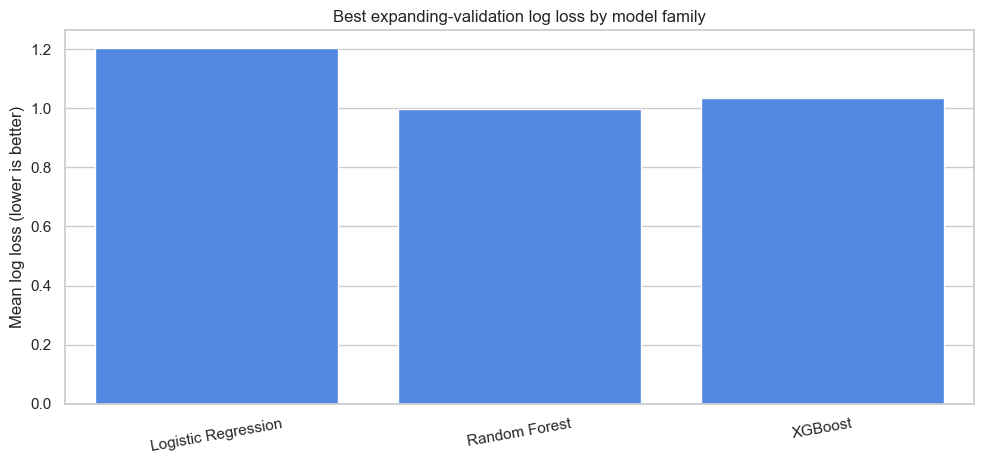

Interpretation: Random Forest has the best mean validation log loss (0.998) and is locked as the champion before the 2026/27 test is opened.


In [12]:
cv_rows = []
tuning_started = time.perf_counter()

for model_name, candidates in MODEL_CANDIDATES.items():
    for candidate_id, params in enumerate(candidates, start=1):
        for validation_season in validation_seasons:
            validation_position = season_order.index(validation_season)
            train_seasons = season_order[:validation_position]
            train_mask = match_meta["Season"].isin(train_seasons).to_numpy()
            validation_mask = match_meta["Season"].eq(validation_season).to_numpy()

            pipeline = make_model_pipeline(model_name, params)
            pipeline.fit(engineered.loc[train_mask], target[train_mask])
            probabilities = aligned_probabilities(pipeline, engineered.loc[validation_mask])
            fold_metrics = probability_metrics(model_name, target[validation_mask], probabilities)
            cv_rows.append(
                {
                    "Model": model_name,
                    "Candidate": candidate_id,
                    "Parameters": json.dumps(params, sort_keys=True),
                    "Validation season": validation_season,
                    **{key: value for key, value in fold_metrics.items() if key != "Model"},
                }
            )
        print(f"Finished {model_name} candidate {candidate_id}/{len(candidates)}")

tuning_seconds = time.perf_counter() - tuning_started
cv_results = pd.DataFrame(cv_rows)
cv_summary = (
    cv_results.groupby(["Model", "Candidate", "Parameters"], as_index=False)
    .agg(
        Mean_log_loss=("Log loss", "mean"),
        SD_log_loss=("Log loss", "std"),
        Mean_macro_F1=("Macro F1", "mean"),
        Mean_balanced_accuracy=("Balanced accuracy", "mean"),
        Mean_draw_recall=("Draw recall", "mean"),
    )
    .sort_values(["Model", "Mean_log_loss", "Mean_macro_F1"], ascending=[True, True, False])
)
best_rows = cv_summary.groupby("Model", sort=False).head(1).reset_index(drop=True)
best_params = {
    row["Model"]: json.loads(row["Parameters"])
    for _, row in best_rows.iterrows()
}
display(cv_summary)
print(f"Chronological selection completed in {tuning_seconds:.1f} seconds.")
print("Selected settings:")
for model_name, params in best_params.items():
    print(f"  {model_name}: {params}")

fig, ax = plt.subplots(figsize=(10, 4.8))
sns.barplot(data=best_rows, x="Model", y="Mean_log_loss", ax=ax, color="#3b82f6")
ax.set(title="Best expanding-validation log loss by model family", xlabel="", ylabel="Mean log loss (lower is better)")
ax.tick_params(axis="x", rotation=10)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "06_cv_model_selection.png", dpi=160, bbox_inches="tight")
plt.show()

cv_champion = best_rows.sort_values(["Mean_log_loss", "Mean_macro_F1"], ascending=[True, False]).iloc[0]
champion_name = str(cv_champion["Model"])
print(
    f"Interpretation: {champion_name} has the best mean validation log loss "
    f"({cv_champion['Mean_log_loss']:.3f}) and is locked as the champion before the 2026/27 test is opened."
)


## 7. Final evaluation on the untouched 2026/27 holdout

Each selected pipeline is now fitted on all four completed seasons (1,520 matches) and evaluated once on the first 70 matches of 2026/27. Two reference baselines are included but do not count as requested models:

- **Training prior:** predicts the development-set class frequencies for every match.
- **Always home:** predicts a home win with probability one, illustrating why accuracy alone is insufficient.


In [13]:
fitted_test_models = {}
test_probabilities = {}
evaluation_rows = []

development_prior = np.bincount(y_development, minlength=3) / len(y_development)
prior_probabilities = np.tile(development_prior, (len(y_test), 1))
always_home_probabilities = np.tile(np.array([1.0, 0.0, 0.0]), (len(y_test), 1))
evaluation_rows.append(probability_metrics("Baseline: training prior", y_test, prior_probabilities))
evaluation_rows.append(probability_metrics("Baseline: always home", y_test, always_home_probabilities))

for model_name, params in best_params.items():
    pipeline = make_model_pipeline(model_name, params)
    started = time.perf_counter()
    pipeline.fit(X_development, y_development)
    fit_seconds = time.perf_counter() - started
    probabilities = aligned_probabilities(pipeline, X_test)
    metrics = probability_metrics(model_name, y_test, probabilities)
    metrics["Fit seconds"] = fit_seconds
    evaluation_rows.append(metrics)
    fitted_test_models[model_name] = pipeline
    test_probabilities[model_name] = probabilities

test_metrics = pd.DataFrame(evaluation_rows).set_index("Model")
display(test_metrics.round(3))

model_only_metrics = test_metrics.loc[list(best_params)]
best_test_accuracy = model_only_metrics["Accuracy"].idxmax()
best_test_logloss = model_only_metrics["Log loss"].idxmin()
champion_metrics = test_metrics.loc[champion_name]
baseline_logloss = test_metrics.loc["Baseline: training prior", "Log loss"]
relative_improvement = (baseline_logloss - champion_metrics["Log loss"]) / baseline_logloss

print(
    f"Interpretation: {champion_name}, selected without looking at this test, records "
    f"accuracy {champion_metrics['Accuracy']:.1%}, macro-F1 {champion_metrics['Macro F1']:.3f}, "
    f"and log loss {champion_metrics['Log loss']:.3f}. Its log-loss change versus the training-prior "
    f"baseline is {relative_improvement:+.1%} (positive means improvement). "
    f"The highest test accuracy belongs to {best_test_accuracy}; the lowest test log loss belongs to {best_test_logloss}."
)
print(
    f"Draw recall for the locked champion is {champion_metrics['Draw recall']:.1%}. "
    "Draws are the minority class and usually the hardest outcome to separate; report this alongside accuracy."
)


,Accuracy,Balanced accuracy,Macro F1,Log loss,Brier (multiclass),Home recall,Draw recall,Away recall,Home F1,Draw F1,Away F1,Fit seconds
Model,,,,,,,,,,,,
Baseline: training prior,0.400,0.333,0.190,1.095,0.664,1.000,0.000,0.000,0.571,0.000,0.000,NaN
Baseline: always home,0.400,0.333,0.190,21.626,1.200,1.000,0.000,0.000,0.571,0.000,0.000,NaN
Logistic Regression,0.443,0.425,0.421,1.151,0.684,0.571,0.250,0.455,0.533,0.323,0.408,0.163
Random Forest,0.443,0.402,0.335,1.022,0.616,0.750,0.000,0.455,0.560,0.000,0.444,0.889
XGBoost,0.457,0.415,0.372,1.028,0.621,0.786,0.050,0.409,0.611,0.077,0.429,0.642


Interpretation: Random Forest, selected without looking at this test, records accuracy 44.3%, macro-F1 0.335, and log loss 1.022. Its log-loss change versus the training-prior baseline is +6.6% (positive means improvement). The highest test accuracy belongs to XGBoost; the lowest test log loss belongs to Random Forest.
Draw recall for the locked champion is 0.0%. Draws are the minority class and usually the hardest outcome to separate; report this alongside accuracy.


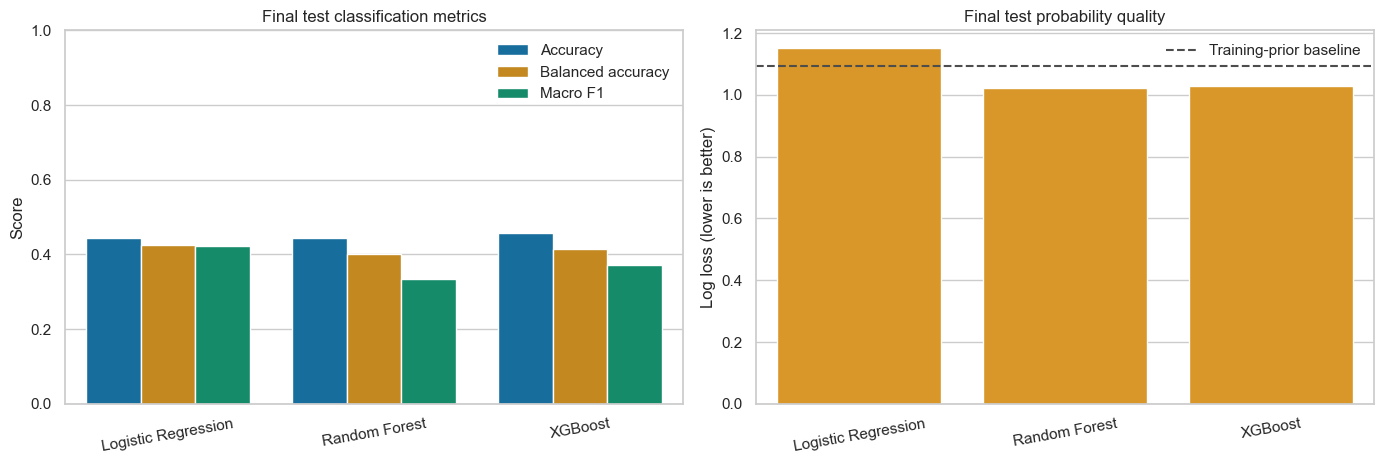

In [14]:
plot_metrics = (
    test_metrics.loc[list(best_params), ["Accuracy", "Balanced accuracy", "Macro F1", "Log loss"]]
    .reset_index()
    .melt(id_vars="Model", var_name="Metric", value_name="Value")
)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.barplot(
    data=plot_metrics[plot_metrics["Metric"].ne("Log loss")],
    x="Model", y="Value", hue="Metric", ax=axes[0]
)
axes[0].set(title="Final test classification metrics", xlabel="", ylabel="Score", ylim=(0, 1))
axes[0].tick_params(axis="x", rotation=10)
axes[0].legend(frameon=False)

sns.barplot(
    data=plot_metrics[plot_metrics["Metric"].eq("Log loss")],
    x="Model", y="Value", ax=axes[1], color="#f59e0b"
)
axes[1].axhline(baseline_logloss, color="0.3", linestyle="--", label="Training-prior baseline")
axes[1].set(title="Final test probability quality", xlabel="", ylabel="Log loss (lower is better)")
axes[1].tick_params(axis="x", rotation=10)
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "07_test_metrics.png", dpi=160, bbox_inches="tight")
plt.show()


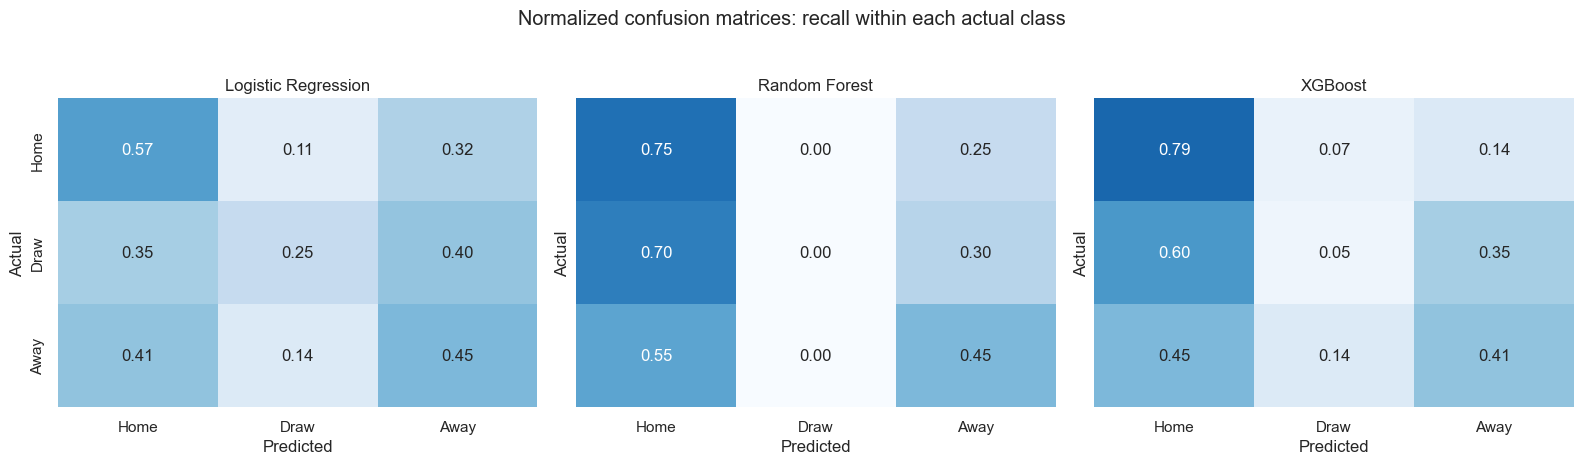

Interpretation: diagonal cells are correct-class recall. Draw recall ranges from 0.0% to 25.0%; off-diagonal draw cells show whether models systematically turn uncertain matches into home or away picks.


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
for ax, (model_name, probabilities) in zip(axes, test_probabilities.items()):
    predictions = np.argmax(probabilities, axis=1)
    matrix = confusion_matrix(y_test, predictions, labels=TARGET_ORDER, normalize="true")
    sns.heatmap(
        matrix, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
        xticklabels=["Home", "Draw", "Away"], yticklabels=["Home", "Draw", "Away"], ax=ax
    )
    ax.set(title=model_name, xlabel="Predicted", ylabel="Actual")
fig.suptitle("Normalized confusion matrices: recall within each actual class", y=1.03)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "08_confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

draw_recalls = test_metrics.loc[list(best_params), "Draw recall"].sort_values(ascending=False)
print(
    "Interpretation: diagonal cells are correct-class recall. Draw recall ranges from "
    f"{draw_recalls.min():.1%} to {draw_recalls.max():.1%}; off-diagonal draw cells show whether "
    "models systematically turn uncertain matches into home or away picks."
)


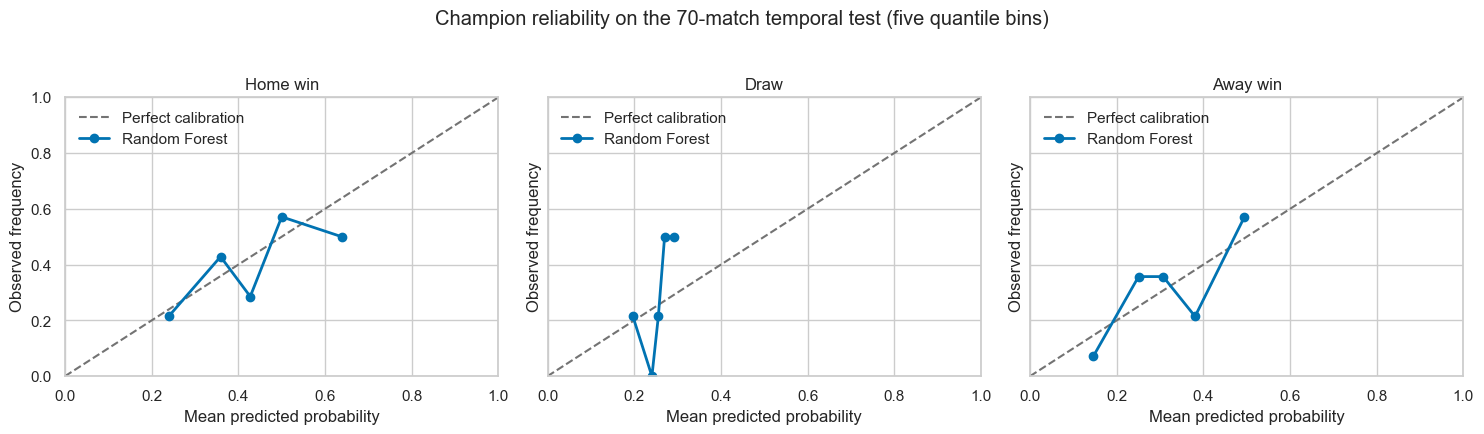

Interpretation: points near the diagonal indicate calibrated probabilities. With only 70 test matches—and roughly 20 draws—these curves are diagnostic rather than definitive. A production version should monitor calibration over more rounds and calibrate only on past data.


In [16]:
# One-vs-rest reliability curves for the validation-selected champion.
champion_test_probabilities = test_probabilities[champion_name]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True, sharey=True)
for class_index, ax in enumerate(axes):
    binary_target = (y_test == class_index).astype(int)
    observed, predicted = calibration_curve(
        binary_target, champion_test_probabilities[:, class_index], n_bins=5, strategy="quantile"
    )
    ax.plot([0, 1], [0, 1], "--", color="0.45", label="Perfect calibration")
    ax.plot(predicted, observed, marker="o", linewidth=2, label=champion_name)
    ax.set(title=TARGET_LABELS[class_index], xlabel="Mean predicted probability", ylabel="Observed frequency")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend(frameon=False)
fig.suptitle("Champion reliability on the 70-match temporal test (five quantile bins)", y=1.03)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "09_champion_calibration.png", dpi=160, bbox_inches="tight")
plt.show()
print(
    "Interpretation: points near the diagonal indicate calibrated probabilities. With only 70 test "
    "matches—and roughly 20 draws—these curves are diagnostic rather than definitive. A production "
    "version should monitor calibration over more rounds and calibrate only on past data."
)


## 8. Model interpretation

Three views answer different questions:

- Logistic coefficients show the direction of association after standardization; they are not causal effects.
- Tree impurity/gain importance shows which transformed inputs the fitted forest and booster used most, but it can favor variables with more split opportunities.
- Test-set permutation importance measures the change in held-out log loss when one raw feature is shuffled. Correlated features can share or dilute importance, so small values do not prove irrelevance.


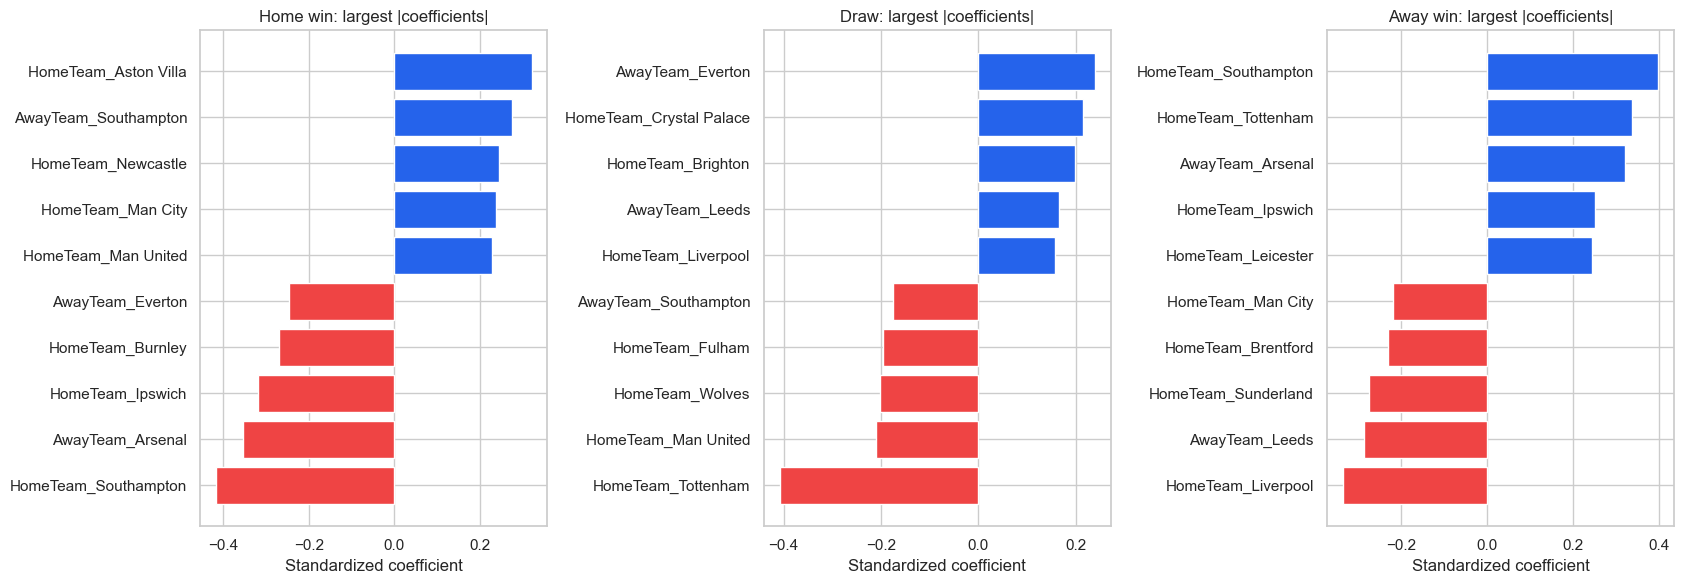

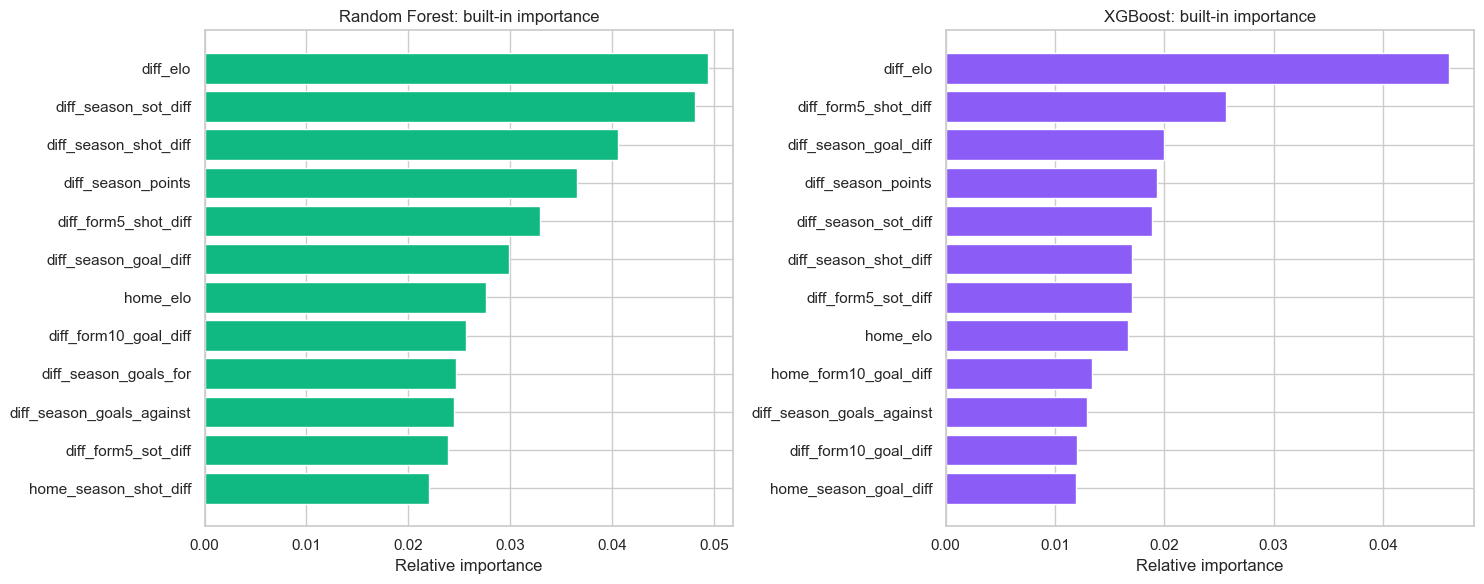

,Feature,Importance_mean,Importance_sd
0,diff_elo,0.007,0.005
1,diff_season_goal_diff,0.007,0.003
2,diff_season_points,0.007,0.005
3,diff_season_goals_against,0.004,0.002
4,home_season_goal_diff,0.004,0.002
5,diff_season_sot_diff,0.003,0.004
6,home_season_points,0.003,0.001
7,diff_form5_sot_diff,0.003,0.002
8,diff_season_shot_diff,0.003,0.004
9,away_season_goal_diff,0.002,0.001


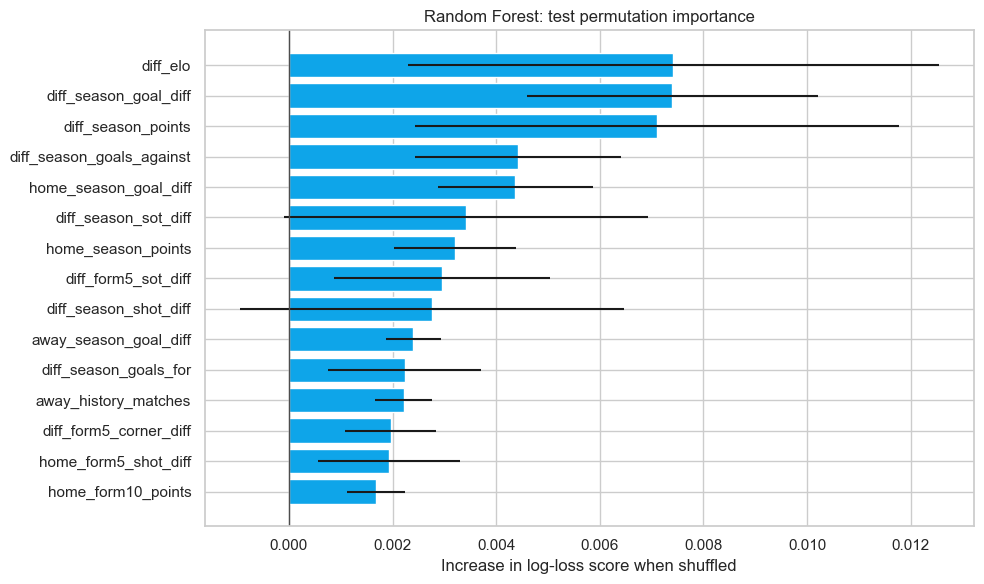

Interpretation: positive permutation values are features that improved held-out probability quality in this test. Read importance as model reliance, not proof that changing a statistic would cause a different result.


In [17]:
# Logistic-regression coefficients by class.
logistic_pipeline = fitted_test_models["Logistic Regression"]
logistic_names = logistic_pipeline.named_steps["preprocessor"].get_feature_names_out()
logistic_coefficients = logistic_pipeline.named_steps["model"].coef_

fig, axes = plt.subplots(1, 3, figsize=(17, 6))
coefficient_rows = []
for class_position, ax in enumerate(axes):
    coefficients = pd.Series(logistic_coefficients[class_position], index=logistic_names)
    selected = coefficients.reindex(coefficients.abs().nlargest(10).index).sort_values()
    colors = ["#ef4444" if value < 0 else "#2563eb" for value in selected]
    ax.barh(selected.index.str.replace("numeric__", "", regex=False).str.replace("categorical__", "", regex=False), selected, color=colors)
    ax.set(title=f"{TARGET_LABELS[class_position]}: largest |coefficients|", xlabel="Standardized coefficient")
    for feature, value in selected.items():
        coefficient_rows.append({"Class": TARGET_LABELS[class_position], "Feature": feature, "Coefficient": value})
fig.tight_layout()
fig.savefig(FIGURE_DIR / "10_logistic_coefficients.png", dpi=160, bbox_inches="tight")
plt.show()

tree_importance_rows = []
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, model_name in zip(axes, ["Random Forest", "XGBoost"]):
    pipeline = fitted_test_models[model_name]
    names = pipeline.named_steps["preprocessor"].get_feature_names_out()
    values = pipeline.named_steps["model"].feature_importances_
    importance = pd.Series(values, index=names).nlargest(12).sort_values()
    ax.barh(
        importance.index.str.replace("numeric__", "", regex=False).str.replace("categorical__", "", regex=False),
        importance.values,
        color="#10b981" if model_name == "Random Forest" else "#8b5cf6",
    )
    ax.set(title=f"{model_name}: built-in importance", xlabel="Relative importance")
    for feature, value in importance.items():
        tree_importance_rows.append({"Model": model_name, "Feature": feature, "Importance": value})
fig.tight_layout()
fig.savefig(FIGURE_DIR / "11_tree_importance.png", dpi=160, bbox_inches="tight")
plt.show()

permutation = permutation_importance(
    fitted_test_models[champion_name],
    X_test,
    y_test,
    scoring="neg_log_loss",
    n_repeats=10,
    random_state=SEED,
    n_jobs=-1,
)
permutation_table = (
    pd.DataFrame(
        {
            "Feature": engineered.columns,
            "Importance_mean": permutation.importances_mean,
            "Importance_sd": permutation.importances_std,
        }
    )
    .sort_values("Importance_mean", ascending=False)
    .reset_index(drop=True)
)
display(permutation_table.head(15))

top_permutation = permutation_table.head(15).sort_values("Importance_mean")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_permutation["Feature"], top_permutation["Importance_mean"], xerr=top_permutation["Importance_sd"], color="#0ea5e9")
ax.axvline(0, color="0.3", linewidth=1)
ax.set(title=f"{champion_name}: test permutation importance", xlabel="Increase in log-loss score when shuffled", ylabel="")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "12_permutation_importance.png", dpi=160, bbox_inches="tight")
plt.show()
print(
    "Interpretation: positive permutation values are features that improved held-out probability "
    "quality in this test. Read importance as model reliance, not proof that changing a statistic "
    "would cause a different result."
)


## 9. Define the official Matchweek 8 forecast set

The supplied CSV has no future rows, so the fixture table is an explicit input with source and cutoff metadata. Times displayed below are **Africa/Lagos (WAT)**. A separate UK-local timestamp is used by the model because the historical CSV stores UK-local kickoff time. The United Kingdom changes from BST to GMT on Sunday 25 October, making the Sunday WAT kickoffs one hour later than their UK listings.

Official source: [Premier League 2026/27 results and fixtures](https://www.premierleague.com/en/matches/results/2026-27).

All ten round rows use the same feature-state snapshot after Tottenham v Coventry completed on 19 October. Predictions from earlier Matchweek 8 fixtures are not allowed to update later ones. Friday's opener is separated as a retrospective frozen backcast; the primary weekend forecast contains the nine fixtures dated 24–25 October.


In [18]:
fixtures = pd.DataFrame(
    [
        ("MW8-01", "2026-10-23 20:00", "2026-10-23 20:00", "Ipswich", "Nott'm Forest", "Backcast — kickoff before notebook date"),
        ("MW8-02", "2026-10-24 12:30", "2026-10-24 12:30", "Aston Villa", "Man City", "Primary weekend forecast"),
        ("MW8-03", "2026-10-24 15:00", "2026-10-24 15:00", "Arsenal", "Everton", "Primary weekend forecast"),
        ("MW8-04", "2026-10-24 15:00", "2026-10-24 15:00", "Coventry", "Fulham", "Primary weekend forecast"),
        ("MW8-05", "2026-10-24 17:30", "2026-10-24 17:30", "Chelsea", "Tottenham", "Primary weekend forecast"),
        ("MW8-06", "2026-10-25 14:00", "2026-10-25 15:00", "Crystal Palace", "Newcastle", "Primary weekend forecast"),
        ("MW8-07", "2026-10-25 14:00", "2026-10-25 15:00", "Hull", "Brentford", "Primary weekend forecast"),
        ("MW8-08", "2026-10-25 14:00", "2026-10-25 15:00", "Liverpool", "Brighton", "Primary weekend forecast"),
        ("MW8-09", "2026-10-25 14:00", "2026-10-25 15:00", "Man United", "Bournemouth", "Primary weekend forecast"),
        ("MW8-10", "2026-10-25 16:30", "2026-10-25 17:30", "Sunderland", "Leeds", "Primary weekend forecast"),
    ],
    columns=["FixtureID", "MatchDateTime", "MatchDateTime_WAT", "HomeTeam", "AwayTeam", "ForecastScope"],
)
fixtures["MatchDateTime"] = pd.to_datetime(fixtures["MatchDateTime"])
fixtures["MatchDateTime_WAT"] = pd.to_datetime(fixtures["MatchDateTime_WAT"])
fixtures["Season"] = TEST_SEASON
fixtures["FixtureSource"] = FIXTURE_SOURCE

current_teams = set(current["HomeTeam"]).union(current["AwayTeam"])
fixture_teams = set(fixtures["HomeTeam"]).union(fixtures["AwayTeam"])
assert len(fixtures) == 10
assert fixtures["FixtureID"].is_unique
assert fixture_teams == current_teams
assert fixtures["MatchDateTime"].min() > raw["MatchDateTime"].max()
assert fixtures["ForecastScope"].eq("Primary weekend forecast").sum() == 9
display(fixtures[["FixtureID", "MatchDateTime_WAT", "HomeTeam", "AwayTeam", "ForecastScope"]])
print(
    "Interpretation: the fixture input covers each of the 20 current-season teams exactly once. "
    "The UK-local model timestamp and WAT display timestamp are deliberately separate. Friday is "
    "a labelled backcast; the nine Saturday/Sunday rows form the primary forecast scope."
)


,FixtureID,MatchDateTime_WAT,HomeTeam,AwayTeam,ForecastScope
0,MW8-01,2026-10-23 20:00:00,Ipswich,Nott'm Forest,Backcast — kickoff before notebook date
1,MW8-02,2026-10-24 12:30:00,Aston Villa,Man City,Primary weekend forecast
2,MW8-03,2026-10-24 15:00:00,Arsenal,Everton,Primary weekend forecast
3,MW8-04,2026-10-24 15:00:00,Coventry,Fulham,Primary weekend forecast
4,MW8-05,2026-10-24 17:30:00,Chelsea,Tottenham,Primary weekend forecast
5,MW8-06,2026-10-25 15:00:00,Crystal Palace,Newcastle,Primary weekend forecast
6,MW8-07,2026-10-25 15:00:00,Hull,Brentford,Primary weekend forecast
7,MW8-08,2026-10-25 15:00:00,Liverpool,Brighton,Primary weekend forecast
8,MW8-09,2026-10-25 15:00:00,Man United,Bournemouth,Primary weekend forecast
9,MW8-10,2026-10-25 17:30:00,Sunderland,Leeds,Primary weekend forecast


Interpretation: the fixture input covers each of the 20 current-season teams exactly once. The UK-local model timestamp and WAT display timestamp are deliberately separate. Friday is a labelled backcast; the nine Saturday/Sunday rows form the primary forecast scope.


## 10. Operational refit and Matchweek 8 prediction

Honest test metrics above remain frozen. For the actual forecast, each selected pipeline is now refitted on **all 1,590 completed matches** through 19 October 2026. This is the appropriate operational use of the newest labels, but these refits are not used to revise the reported test scores.


In [19]:
frozen_feature_builder = FrozenEPLFeatureBuilder(
    historical_state=historical_state,
    feature_columns=engineered.columns.tolist(),
    rolling_window=ROLLING_WINDOW,
    long_window=LONG_WINDOW,
)
fixture_features = frozen_feature_builder.transform(fixtures)
assert fixture_features.index.tolist() == fixtures["FixtureID"].tolist()
assert fixture_features[["HomeTeam", "AwayTeam"]].reset_index(drop=True).equals(
    fixtures[["HomeTeam", "AwayTeam"]].reset_index(drop=True)
)
operational_models = {}
prediction_rows = []

for model_name, params in best_params.items():
    pipeline = make_model_pipeline(model_name, params)
    pipeline.fit(engineered, target)
    probabilities = aligned_probabilities(pipeline, fixture_features)
    operational_models[model_name] = pipeline

    for fixture_index, probability in enumerate(probabilities):
        ordered = np.sort(probability)[::-1]
        predicted_class = int(np.argmax(probability))
        entropy = -float(np.sum(np.clip(probability, 1e-12, 1) * np.log(np.clip(probability, 1e-12, 1)))) / math.log(3)
        fixture_row = fixtures.iloc[fixture_index]
        prediction_rows.append(
            {
                "FixtureID": fixture_row["FixtureID"],
                "MatchDateTime_UK": fixture_row["MatchDateTime"],
                "MatchDateTime_WAT": fixture_row["MatchDateTime_WAT"],
                "HomeTeam": fixture_row["HomeTeam"],
                "AwayTeam": fixture_row["AwayTeam"],
                "ForecastScope": fixture_row["ForecastScope"],
                "Model": model_name,
                "P_Home": probability[0],
                "P_Draw": probability[1],
                "P_Away": probability[2],
                "Prediction": TARGET_SHORT[predicted_class],
                "PredictionLabel": TARGET_LABELS[predicted_class],
                "Confidence": ordered[0],
                "Margin": ordered[0] - ordered[1],
                "NormalizedEntropy": entropy,
                "DataCutoff": DATA_CUTOFF,
            }
        )

predictions_long = pd.DataFrame(prediction_rows)
champion_predictions = predictions_long.loc[predictions_long["Model"].eq(champion_name)].reset_index(drop=True)
upcoming_predictions_long = predictions_long.loc[predictions_long["ForecastScope"].eq("Primary weekend forecast")].reset_index(drop=True)
upcoming_champion_predictions = champion_predictions.loc[
    champion_predictions["ForecastScope"].eq("Primary weekend forecast")
].reset_index(drop=True)
friday_backcast = champion_predictions.loc[champion_predictions["ForecastScope"].str.startswith("Backcast")]
print("Primary Saturday/Sunday forecast (nine fixtures):")
display(
    upcoming_champion_predictions[
        ["MatchDateTime_WAT", "HomeTeam", "AwayTeam", "P_Home", "P_Draw", "P_Away", "PredictionLabel", "Confidence", "Margin"]
    ].style.format(
        {"P_Home": "{:.1%}", "P_Draw": "{:.1%}", "P_Away": "{:.1%}", "Confidence": "{:.1%}", "Margin": "{:.1%}"}
    )
)
print("Friday opener retained separately as a frozen backcast:")
display(friday_backcast[["MatchDateTime_WAT", "HomeTeam", "AwayTeam", "P_Home", "P_Draw", "P_Away", "PredictionLabel"]])

agreement = (
    upcoming_predictions_long.pivot_table(
        index=["FixtureID", "MatchDateTime_WAT", "HomeTeam", "AwayTeam"],
        columns="Model", values="Prediction", aggfunc="first"
    )
    .reset_index()
)
model_columns = list(best_params)
agreement["ModelsAgree"] = agreement[model_columns].nunique(axis=1).eq(1)
display(agreement)

pick_counts = upcoming_champion_predictions["PredictionLabel"].value_counts()
mean_confidence = upcoming_champion_predictions["Confidence"].mean()
low_margin = upcoming_champion_predictions.nsmallest(3, "Margin")[["HomeTeam", "AwayTeam", "Margin"]]
print(
    f"Interpretation: {champion_name} makes {pick_counts.to_dict()} with mean top probability "
    f"{mean_confidence:.1%}. {int(agreement['ModelsAgree'].sum())} of 9 primary fixtures receive the same "
    "H/D/A pick from all three model families."
)
print("The three smallest probability margins—highest model uncertainty—are:")
display(low_margin.style.format({"Margin": "{:.1%}"}))


Primary Saturday/Sunday forecast (nine fixtures):


,MatchDateTime_WAT,HomeTeam,AwayTeam,P_Home,P_Draw,P_Away,PredictionLabel,Confidence,Margin
0,2026-10-24 12:30:00,Aston Villa,Man City,22.3%,29.0%,48.7%,Away win,48.7%,19.8%
1,2026-10-24 15:00:00,Arsenal,Everton,51.5%,26.8%,21.7%,Home win,51.5%,24.8%
2,2026-10-24 15:00:00,Coventry,Fulham,30.3%,27.2%,42.5%,Away win,42.5%,12.3%
3,2026-10-24 17:30:00,Chelsea,Tottenham,46.0%,34.0%,20.1%,Home win,46.0%,12.0%
4,2026-10-25 15:00:00,Crystal Palace,Newcastle,35.5%,27.1%,37.4%,Away win,37.4%,1.9%
5,2026-10-25 15:00:00,Hull,Brentford,41.2%,23.7%,35.1%,Home win,41.2%,6.1%
6,2026-10-25 15:00:00,Liverpool,Brighton,33.6%,28.6%,37.8%,Away win,37.8%,4.2%
7,2026-10-25 15:00:00,Man United,Bournemouth,46.4%,26.9%,26.7%,Home win,46.4%,19.5%
8,2026-10-25 17:30:00,Sunderland,Leeds,32.4%,24.0%,43.6%,Away win,43.6%,11.3%


Friday opener retained separately as a frozen backcast:


,MatchDateTime_WAT,HomeTeam,AwayTeam,P_Home,P_Draw,P_Away,PredictionLabel
0,2026-10-23 20:00:00,Ipswich,Nott'm Forest,0.380,0.277,0.343,Home win


Model,FixtureID,MatchDateTime_WAT,HomeTeam,AwayTeam,Logistic Regression,Random Forest,XGBoost,ModelsAgree
0,MW8-02,2026-10-24 12:30:00,Aston Villa,Man City,A,A,A,True
1,MW8-03,2026-10-24 15:00:00,Arsenal,Everton,H,H,H,True
2,MW8-04,2026-10-24 15:00:00,Coventry,Fulham,A,A,A,True
3,MW8-05,2026-10-24 17:30:00,Chelsea,Tottenham,H,H,H,True
4,MW8-06,2026-10-25 15:00:00,Crystal Palace,Newcastle,A,A,A,True
5,MW8-07,2026-10-25 15:00:00,Hull,Brentford,H,H,H,True
6,MW8-08,2026-10-25 15:00:00,Liverpool,Brighton,D,A,D,False
7,MW8-09,2026-10-25 15:00:00,Man United,Bournemouth,H,H,H,True
8,MW8-10,2026-10-25 17:30:00,Sunderland,Leeds,H,A,A,False


Interpretation: Random Forest makes {'Away win': 5, 'Home win': 4} with mean top probability 43.9%. 7 of 9 primary fixtures receive the same H/D/A pick from all three model families.
The three smallest probability margins—highest model uncertainty—are:


,HomeTeam,AwayTeam,Margin
4,Crystal Palace,Newcastle,1.9%
6,Liverpool,Brighton,4.2%
5,Hull,Brentford,6.1%


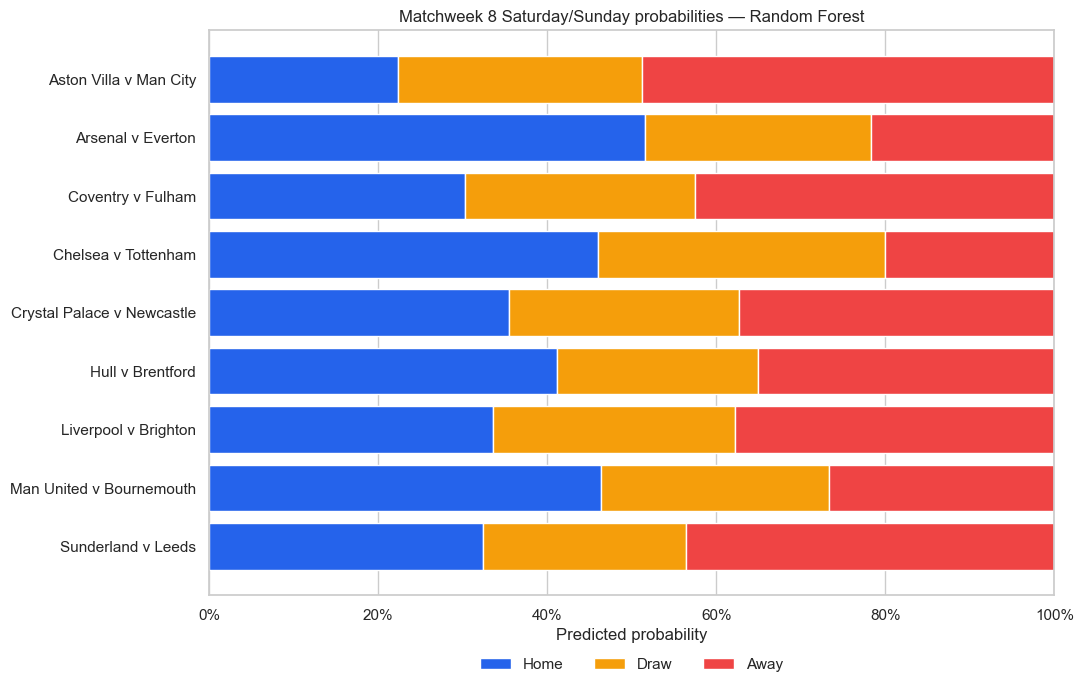

Interpretation: the stacked bars force all three outcomes to remain visible. A largest segment is a model pick, not certainty; a narrow lead over the second-largest segment is explicitly captured by the Margin column.


In [20]:
probability_plot = upcoming_champion_predictions.copy()
probability_plot["Fixture"] = probability_plot["HomeTeam"] + " v " + probability_plot["AwayTeam"]
probability_plot = probability_plot.iloc[::-1]

fig, ax = plt.subplots(figsize=(11, 7))
left = np.zeros(len(probability_plot))
for column, label, color in [
    ("P_Home", "Home", "#2563eb"),
    ("P_Draw", "Draw", "#f59e0b"),
    ("P_Away", "Away", "#ef4444"),
]:
    values = probability_plot[column].to_numpy()
    ax.barh(probability_plot["Fixture"], values, left=left, label=label, color=color)
    left += values
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
ax.set(title=f"Matchweek 8 Saturday/Sunday probabilities — {champion_name}", xlabel="Predicted probability", ylabel="")
ax.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.16))
fig.tight_layout()
fig.savefig(FIGURE_DIR / "13_matchweek8_probabilities.png", dpi=160, bbox_inches="tight")
plt.show()
print(
    "Interpretation: the stacked bars force all three outcomes to remain visible. A largest segment "
    "is a model pick, not certainty; a narrow lead over the second-largest segment is explicitly "
    "captured by the Margin column."
)


## 11. Persist and verify the complete modeling artifacts

A saved estimator alone is insufficient. Reproducing a forecast also needs the fitted preprocessing, feature column order, label mapping, cutoff, fixture source, selected parameters, historical state, and the exact raw-fixture transformer. The champion bundle contains a versioned `FrozenEPLFeatureBuilder`, and reload verification starts again from raw fixture rows rather than reusing the in-memory engineered matrix.


In [21]:
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
model_paths = {}
safe_names = {
    "Logistic Regression": "logistic_regression_pipeline.joblib",
    "Random Forest": "random_forest_pipeline.joblib",
    "XGBoost": "xgboost_pipeline.joblib",
}
for model_name, pipeline in operational_models.items():
    path = ARTIFACT_DIR / safe_names[model_name]
    joblib.dump(pipeline, path)
    model_paths[model_name] = str(path.resolve())

operational_models["XGBoost"].named_steps["model"].save_model(ARTIFACT_DIR / "xgboost_native_model.json")
joblib.dump(historical_state, ARTIFACT_DIR / "historical_feature_state.joblib")

champion_bundle = {
    "pipeline": operational_models[champion_name],
    "champion_name": champion_name,
    "feature_columns": engineered.columns.tolist(),
    "categorical_features": categorical_features,
    "numeric_features": numeric_features,
    "target_order": TARGET_ORDER,
    "target_labels": TARGET_LABELS,
    "selected_parameters": best_params[champion_name],
    "data_cutoff": DATA_CUTOFF,
    "fixture_source": FIXTURE_SOURCE,
    "historical_feature_state": historical_state,
    "feature_builder": frozen_feature_builder,
    "feature_builder_version": FEATURE_BUILDER_VERSION,
    "raw_fixture_contract": ["FixtureID", "MatchDateTime", "HomeTeam", "AwayTeam", "Season"],
    "feature_time_convention": "timezone-naive UK-local kickoff; WAT is display-only",
    "package_versions": PACKAGE_VERSIONS,
    "random_seed": SEED,
}
champion_path = ARTIFACT_DIR / "champion_model_bundle.joblib"
joblib.dump(champion_bundle, champion_path)

predictions_path = ARTIFACT_DIR / "matchweek8_predictions_all_models.csv"
champion_predictions_path = ARTIFACT_DIR / "matchweek8_champion_predictions.csv"
upcoming_predictions_path = ARTIFACT_DIR / "upcoming_predictions_all_models.csv"
upcoming_champion_path = ARTIFACT_DIR / "upcoming_champion_predictions.csv"
cv_path = ARTIFACT_DIR / "chronological_cv_results.csv"
metrics_path = ARTIFACT_DIR / "final_test_metrics.csv"
importance_path = ARTIFACT_DIR / "champion_permutation_importance.csv"
fixtures_path = ARTIFACT_DIR / "matchweek8_fixtures_wat.csv"
predictions_long.to_csv(predictions_path, index=False)
champion_predictions.to_csv(champion_predictions_path, index=False)
upcoming_predictions_long.to_csv(upcoming_predictions_path, index=False)
upcoming_champion_predictions.to_csv(upcoming_champion_path, index=False)
cv_results.to_csv(cv_path, index=False)
test_metrics.reset_index().to_csv(metrics_path, index=False)
permutation_table.to_csv(importance_path, index=False)
fixtures[["FixtureID", "MatchDateTime_WAT", "MatchDateTime", "HomeTeam", "AwayTeam", "Season", "ForecastScope", "FixtureSource"]].rename(
    columns={"MatchDateTime": "MatchDateTime_UK"}
).to_csv(fixtures_path, index=False)

dataset_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
metadata = {
    "project": "EPL three-class pre-match outcome prediction",
    "dataset": str(DATA_PATH.resolve()),
    "dataset_sha256": dataset_sha256,
    "rows": len(raw),
    "data_cutoff": DATA_CUTOFF,
    "forecast_round": "2026/27 Matchweek 8",
    "fixture_source": FIXTURE_SOURCE,
    "feature_builder_version": FEATURE_BUILDER_VERSION,
    "pipeline_input": "Engineered feature frame; use feature_builder in champion bundle for raw fixtures.",
    "feature_time_convention": "timezone-naive UK-local kickoff; WAT is display-only",
    "target_mapping": {str(key): value for key, value in TARGET_LABELS.items()},
    "validation_seasons": validation_seasons,
    "test_season": TEST_SEASON,
    "champion": champion_name,
    "best_parameters": best_params,
    "package_versions": PACKAGE_VERSIONS,
    "random_seed": SEED,
    "notes": [
        "All match statistics are used only as strictly lagged historical aggregates.",
        "Final test metrics are from models fit through 2025/26; operational models are refit through matches completed on 19 Oct 2026.",
        "The Friday Matchweek 8 fixture is exported as a backcast, separate from the nine primary weekend forecasts.",
    ],
}
metadata_path = ARTIFACT_DIR / "model_metadata.json"
metadata_path.write_text(json.dumps(metadata, indent=2, default=str), encoding="utf-8")

reloaded = joblib.load(champion_path)
shuffled_fixtures = fixtures.sample(frac=1, random_state=SEED).reset_index(drop=True)
reloaded_fixture_features = reloaded["feature_builder"].transform(shuffled_fixtures)
shuffled_probabilities = aligned_probabilities(reloaded["pipeline"], reloaded_fixture_features)
reloaded_probabilities = (
    pd.DataFrame(shuffled_probabilities, index=reloaded_fixture_features.index)
    .loc[fixtures["FixtureID"].tolist()]
    .to_numpy()
)
in_memory_probabilities = champion_predictions[["P_Home", "P_Draw", "P_Away"]].to_numpy()
max_reload_difference = float(np.max(np.abs(reloaded_probabilities - in_memory_probabilities)))
assert max_reload_difference < 1e-12

artifact_inventory = pd.DataFrame(
    [
        {"Artifact": path.name, "Size_KB": path.stat().st_size / 1024}
        for path in sorted(ARTIFACT_DIR.glob("*")) if path.is_file()
    ]
)
display(artifact_inventory)
print(f"Reload verification passed; maximum probability difference = {max_reload_difference:.3e}")
print(f"Champion bundle: {champion_path.resolve()}")


,Artifact,Size_KB
0,champion_model_bundle.joblib,"2,954.582"
1,champion_permutation_importance.csv,5.948
2,chronological_cv_results.csv,8.939
3,final_test_metrics.csv,1.048
4,historical_feature_state.joblib,414.390
5,logistic_regression_pipeline.joblib,22.494
6,matchweek8_champion_predictions.csv,3.288
7,matchweek8_fixtures_wat.csv,1.648
8,matchweek8_predictions_all_models.csv,9.493
9,model_metadata.json,2.044


Reload verification passed; maximum probability difference = 3.331e-16
Champion bundle: C:\Users\obinn\Documents\New project 3\output\jupyter-notebook\artifacts\champion_model_bundle.joblib


In [22]:
# Compact executive summary generated from the actual run.
summary = {
    "Rows / seasons": f"{len(raw):,} matches across {len(season_order)} seasons",
    "Forecast cutoff": DATA_CUTOFF,
    "Validation-selected champion": champion_name,
    "Champion test accuracy": f"{champion_metrics['Accuracy']:.1%}",
    "Champion test macro-F1": f"{champion_metrics['Macro F1']:.3f}",
    "Champion test log loss": f"{champion_metrics['Log loss']:.3f}",
    "Champion draw recall": f"{champion_metrics['Draw recall']:.1%}",
    "Primary weekend forecasts": "9 (Friday opener stored separately as a backcast)",
    "Unanimous model picks": f"{int(agreement['ModelsAgree'].sum())}/9",
    "Saved champion": str(champion_path.resolve()),
}
display(pd.Series(summary, name="Run summary").to_frame())


,Run summary
Rows / seasons,"1,590 matches across 5 seasons"
Forecast cutoff,Through matches completed on 19 Oct 2026 (late...
Validation-selected champion,Random Forest
Champion test accuracy,44.3%
Champion test macro-F1,0.335
Champion test log loss,1.022
Champion draw recall,0.0%
Primary weekend forecasts,9 (Friday opener stored separately as a backcast)
Unanimous model picks,7/9
Saved champion,C:\Users\obinn\Documents\New project 3\output\...


## 12. Conclusions, limitations, and production roadmap

### What this prototype establishes

- The raw dataset is structurally complete for four seasons and seven rounds of 2026/27, with no missing values, duplicates, or outcome inconsistencies.
- Same-match statistics are highly informative but unusable at kickoff. Converting them into strict historical state avoids the most serious form of leakage.
- Chronological validation measures how each family travels into a later season; the current-season holdout exposes both performance and drift.
- The forecast is probability-based. Confidence and margin make uncertainty visible instead of hiding it behind a single H/D/A label.
- All three full preprocessing/model pipelines, the feature state, the validation results, the test metrics, the predictions, metadata, and a reload-tested champion bundle are saved.

### Important limitations

- The final test contains only 70 matches, so metric ranking can change as the season develops.
- The data source is not embedded in the CSV; official-result provenance should be added before production.
- Promoted/cold-start clubs have shallow Premier League histories in this extract.
- No injury, lineup, transfer, schedule-congestion beyond rest days, expected-goals, market-odds, or advanced-event inputs are present.
- Reliability curves are based on a small sample. Probability calibration should be monitored and, if necessary, learned only from past validation periods.
- The validation-selected random forest had **0% draw recall** on this 70-match test. Its probabilities beat the prior baseline on log loss, but its argmax labels did not identify a draw; that weakness must be monitored rather than hidden by overall accuracy.
- Model associations and feature importance are not causal explanations.

### Before production

1. Move the historical state-update logic into the versioned feature module and add unit tests for cutoff, simultaneous kickoffs, season changes, and name normalization.
2. Automate official results and fixture ingestion with schema validation and immutable raw snapshots.
3. Add experiment tracking, artifact versioning, and a model registry.
4. Calibrate probabilities on rolling past windows; monitor log loss, class recall, calibration error, drift, and data freshness.
5. Add an inference service or scheduled batch job with idempotent outputs and clear as-of timestamps.
6. Retrain only after results are final, never during an active round unless the product explicitly uses a new cutoff.
7. Compare against stronger football baselines (Poisson/Dixon–Coles, bookmaker-implied probabilities where legally available, and richer xG features).
